[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_RobustnessBenchmark_Zhang2025.ipynb)

# QNN robustness benchmarking: Mask-FGSM, robustness bounds, adversarial training (Zhang et al. 2025) step by step

**Paper.** Hai-Feng Zhang, Zhao-Yun Chen, Peng Wang, Liang-Liang Guo, Tian-Le Wang, Xiao-Yan Yang, Ren-Ze Zhao, Ze-An Zhao, Sheng Zhang, Lei Du, Hao-Ran Tao, Zhi-Long Jia, Wei-Cheng Kong, Huan-Yu Liu, Athanasios V. Vasilakos, Yang Yang, Yu-Chun Wu, Ji Guan, Peng Duan and Guo-Ping Guo,
*Experimental robustness benchmarking of quantum neural networks on a superconducting quantum processor*, Science China Physics, Mechanics & Astronomy (2025), DOI [10.1007/s11433-025-2943-6](https://doi.org/10.1007/s11433-025-2943-6), arXiv:2505.16714.

**What the paper does.** It trains 20-qubit quantum neural network (QNN) classifiers *on a superconducting chip* (handwritten letters "Q" vs "T" from EMNIST, and a synthetic "linear cluster excitation identification", LCEI, task), attacks them with a new sparse white-box attack (**Mask-FGSM**), brackets each sample's robustness radius between an analytic **lower bound** and an attack-derived **upper bound**, defines a logit-sensitivity **robustness score** `R_adv`, shows that **adversarial training** raises `R_adv`, and argues that hardware noise acts as gradient masking so that the noisy QNN looks more robust than a classical network.

**What this notebook does.** No quantum processor is used here. Every experiment is re-run on **exact simulators** (a fast statevector engine that is checked gate by gate against Qiskit) and, for the noise claim, on **density-matrix simulators with a device-like noise model** (the paper's own device parameters, and an IBM fake backend). The numbers printed in the paper's hardware figures are therefore *the paper's values to compare against*, not something this notebook can reproduce; the simulator numbers show which claims survive without a chip, and which depend on it. The attack, the bounds, the score and adversarial training are implemented exactly as the paper's equations describe.

**How to run.** Google Colab, **CPU runtime**, `Runtime -> Run all`. `FAST_MODE = True` is a class demo of about 10 minutes on a CPU (measured: 9 min); `FAST_MODE = False` (the setting of this saved, executed version) uses the larger budgets listed in the configuration cell and took 23 to 47 minutes on a CPU shared with other jobs (about 23 minutes on a quiet machine). A `HF_TOKEN` is *not* required (the EMNIST mirror is public); if you ever point the notebook at a gated dataset, add your own token under Colab *Secrets* as `HF_TOKEN`. An `IBM_TOKEN` is optional and only used for an optional real-hardware cell that is skipped when empty.

**What you get at the end.** Training curves, the attack-accuracy curves, the robustness-bound experiment (`R_UB` vs `R_LB`), the sensitivity/robustness-score analysis for a clean and an adversarially trained QNN, a classical-network comparison, a noise study, and a final table that puts the paper's numbers next to the notebook's with a verdict per claim.

## The paper in one page

**Problem.** Quantum classifiers inherit adversarial vulnerability. The paper wants (i) a hardware-friendly attack, (ii) a way to benchmark robustness *experimentally*, (iii) a quantitative check of adversarial training, and (iv) a QNN-vs-classical comparison.

**Decision.** Binary classification. The QNN outputs `p = (<Z> + 1) / 2` from the Pauli-Z expectation of one output qubit; class 1 if `p >= 0.5`. Loss: cross-entropy.

**Model.** Hardware-efficient circuit: blocks of decreasing width (Fig. S1: five blocks of decreasing size, then a final `Rx` before measurement; 181 trainable parameters on 20 qubits). Each block is a layer of SU(2) gates (`Rz Rx(pi/2) Rz Rx(pi/2) Rz`, virtual-Z) followed by nearest-neighbour CZ gates. For images, **data re-uploading**: the angle of the i-th `Rz` is `phi_i = x_i + theta_i` (pixel plus trainable offset); 169 of the 181 parameters carry pixels (13x13 centre of a 15x15 image), 12 are variational only. For LCEI the state `Rx(alpha) CZ-chain |+>^n` is prepared first and all 181 parameters are variational.

**Data.** EMNIST letters "Q" and "T": 600 images (300 per class), 500 train / 100 test. LCEI: 300 synthetic states, 150 `alpha` values drawn uniformly from `[0, 3pi/8]` ("non-excited") and `[5pi/8, pi]` ("excited"), 200 train / 100 test.

**Training.** Mini-batch Adam, `beta = (0.9, 0.999)`; EMNIST `lr = 0.1`, batch 100; LCEI `lr = 0.03`, batch 50; clean and adversarial training use identical settings.

**Attack (Mask-FGSM, Eq. 1).** `x' = x + eps * (M * sign(grad_x L))` with a binary mask `M` marking the top `r * dim(x)` coordinates of the dataset-averaged absolute input gradient (`r ~ 0.15` for EMNIST, computed on 20 samples; the central qubits `Q7..Q14` for LCEI). The normalised strength is `eps_hat = eps / (x_max - x_min)`.

**Robustness bounds.** Lower bound (Eq. 2): `R_LB = (1/2) (sqrt(p1) - sqrt(p2))^2` with `p1 = max(p, 1-p)`, `p2 = 1 - p1`. Upper bound `R_UB`: infidelity `D(rho, sigma) = 1 - F` of the output-qubit state at the perturbation `eps_hat*` where the prediction first flips (`p = 0.5`). Hardware claim: on ten samples `R_UB - R_LB` is `2.96e-3` (EMNIST) and `3.25e-3` (LCEI).

**Robustness score (Eqs. 3-4).** Quantum logit `L = ln(p / (1 - p))`, sensitivity `S = Delta L / eps_hat`, `R_adv = mean over samples of 1 / (1 + exp(S))`, evaluated on 200 samples (100 per class).

**Adversarial training.** 200 Mask-FGSM samples (100 per class) are generated once; every mini-batch is 50 % legitimate and 50 % adversarial.

**Headline claims (hardware).** Clean accuracy: EMNIST 98 % train / 96 % test, LCEI 100 % / 100 %. After adversarial training: EMNIST 88 % (legitimate) / 87 % (adversarial), LCEI 100 % / 100 %. Gap `R_UB - R_LB`: `2.96e-3` / `3.25e-3`. Pearson correlation between `S` and `cos(delta, grad L)`: 0.86 (EMNIST), 0.785 (LCEI). `R_adv` clean -> adversarially trained: EMNIST `8.90e-3` -> `0.330`, LCEI `0.105` -> `0.339`. Noiseless matched-size simulation (Table I): no consistent QNN advantage over a classical FNN (both `~0.07`); the measured hardware QNN beats a classical FNN by more than 64x, which the paper attributes to noise-induced gradient attenuation (Eq. 5).

### What follows the paper and what had to be chosen

The paper's code is not public and several details are only given in figures. Everything marked `# CHOICE:` in the code is a decision made here.

| Item | Paper | This notebook |
|---|---|---|
| Hardware | 72-qubit superconducting chip, 20 qubits, real shots, QST, readout mitigation | exact statevector simulation (checked against Qiskit); noise study with `AerSimulator` density matrices |
| Qubits / depth | 20 qubits, five blocks (20,16,12,8,4 qubits wide), 181 parameters (the paper-scale count is reproduced in a cell below) | `N_QUBITS = 8`, four blocks of width 8,6,4,2, each width repeated `REPEAT = 3` times (12 SU(2)+CZ layers), so the circuit also has **181 parameters** (`# CHOICE:` a 20-qubit statevector with back-propagation is too slow for a CPU notebook; the paper's own numerical study used a 12-qubit model) |
| Image size / encoded pixels | 15x15, central 13x13 = 169 | 9x9 = 81 pixels (`# CHOICE:` also the 9x9 size the paper uses for its classical FNN) |
| Which `Rz` carries which pixel | not specified | pixels fill the `Rz` slots in the order (block, qubit, slot); the remaining slots are variational only. A fixed `Rx(pi/2)` on every qubit precedes block 0 so the first `Rz` is not a global phase |
| Pixel -> angle scale | not specified | `angle = pixel` in radians (`x_max - x_min = 1`); `# CHOICE:` a scale of pi trained much worse in preliminary runs (about 70 % accuracy) |
| Output qubit | "central qubit" | the lower middle qubit of the narrowest block |
| Optimiser | Adam, EMNIST `lr 0.1`, batch 100; LCEI `lr 0.03`, batch 50 | Adam; smaller batches and more steps per epoch (`# CHOICE:` the simulator model is smaller, see configuration cell) |
| Epochs, initial parameters | not given | see configuration cell; `theta ~ U(-pi, pi)` |
| Attack mask | `r ~ 0.15`; central qubits Q7..Q14 for LCEI | `r = 0.15` of the 81 pixels from 20 test samples; LCEI: top 40 % of the `alpha` entries (8 of 20 in the paper) from the same 20 calibration test samples |
| Attack strength for the adversarial set | not given | smallest `eps_hat` in a grid for which the clean model keeps <= 25 % accuracy on the 200 generated samples (`# CHOICE:`) |
| Adversarial training start | not given | from the same initial parameters as the clean model, same hyper-parameters, 50 % legitimate / 50 % adversarial mini-batches |
| Sensitivity `S` | `Delta L / eps_hat` | absolute slope (through the origin) of the true-class logit change over a small `eps_hat` grid (`# CHOICE:`); `S >= 0`. Fig. 3 protocol: both models are moved along the *same targeted* `delta` (Mask-FGSM direction of the clean model); the stricter adaptive variant (adversarial model attacked along its own gradient) is reported as an extra row |
| Pearson correlation of Fig. 3g,h | `S` vs `cos(delta, grad L)`, 200 samples | pooled over the clean and the adversarially trained model (per-model values are printed too) |
| Matched-size re-uploading QNN (Table I) | 3 qubits, `Nr` blocks of 81 data gates, details in the supplement | `# CHOICE:` 9 layers per block, `Ry Rz Ry` per qubit per layer, gate `j` takes input `j mod 81`, CZ chain after each layer, `<Z>` on qubit 0; `w ~ N(0.5, 0.1)`, `b ~ N(0, 0.3)`, Adam `lr 0.03` (a larger initialisation did not train for `Nr >= 4`) |
| `R_UB` | cos^2 fits to hardware data, QST on the output qubit | exact output-qubit Bloch vector at the exact crossing `p = 0.5` found by bisection |
| 200 samples for `R_adv` | 100 per class | 100 per class drawn from all 600 EMNIST images / all 300 LCEI states |
| Classical FNN | 81-2-1, 167 parameters | the same architecture in PyTorch; Table I re-done with a 3-qubit re-uploading QNN |
| Noise | the chip | (i) paper device parameters (Table S1) as an Aer noise model on a 6-qubit LCEI QNN, (ii) IBM `FakeSherbrooke` noise model, (iii) the analytic contraction of Eq. 5 applied to the 10-qubit EMNIST model |

In [1]:
# Installs, pinned to the versions this notebook was tested with. Colab already ships numpy, pandas,
# scikit-learn, scipy, matplotlib, pillow and torch. The guard keeps a local environment untouched.
import sys, importlib
IN_COLAB = "google.colab" in sys.modules
def _have(m):
    try:
        importlib.import_module(m); return True
    except Exception:
        return False
if IN_COLAB or not (_have("qiskit") and _have("qiskit_aer") and _have("qiskit_ibm_runtime") and _have("pylatexenc")):
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "qiskit-aer==0.17.2",
                    "qiskit-ibm-runtime==0.50.0", "pylatexenc", "huggingface_hub"], check=False)
    print("Installed pinned packages (restart the runtime once if an import below fails).")
else:
    print("Required packages already available.")

Required packages already available.


In [2]:
# ----------------------------- configuration cell (every tunable constant) -----------------------------
SEED = 42
FAST_MODE = False           # True: class demo (small budgets); False: the larger budgets in the right-hand column

# Quantum model (paper: 20 qubits, 181 parameters; see the "paper vs notebook" table)
N_QUBITS   = 8              # CHOICE: simulator-friendly width (paper 20, its own numerical study 12)
N_BLOCKS   = 4              # CHOICE: blocks of decreasing width (paper: five blocks at 20 qubits)
CUT        = 1              # qubits removed per side per block (paper-scale model: 2)
REPEAT     = 3              # CHOICE: each width is used three times (SU(2)+CZ): 181 parameters like the paper
IMG        = 9              # CHOICE: 9x9 images -> 81 encoded pixels
N_PER_CLASS = 300           # paper: 300 Q + 300 T
N_TRAIN    = 500            # paper: 500 train / 100 test
LCEI_PER_CLASS, LCEI_TRAIN = 150, 200

# Training (paper: EMNIST lr 0.1 / batch 100, LCEI lr 0.03 / batch 50, Adam)
EPOCHS_EMNIST = 8   if FAST_MODE else 40       # CHOICE
EPOCHS_LCEI   = 8   if FAST_MODE else 25       # CHOICE
LR_EMNIST, BATCH_EMNIST = 0.05, 25             # CHOICE: more steps per epoch than the paper's batch of 100
LR_LCEI,   BATCH_LCEI   = 0.03, 25             # CHOICE
MASK_R_EMNIST, MASK_R_LCEI = 0.15, 0.40        # paper: r ~ 0.15 (EMNIST); 8 of 20 qubits (LCEI)
N_MASK_SAMPLES = 20                            # paper: gradients averaged over 20 samples

# Attack / benchmark
EPS_SENS = (0.01, 0.02, 0.03)                  # CHOICE: small eps_hat grid for the sensitivity slope (units of x_max - x_min)
EPS_TRAIN_GRID = (0.05, 0.1, 0.15, 0.2, 0.3, 0.4)
ADV_PER_CLASS = 100                            # paper: 200 adversarial samples, 100 per class
BENCH_PER_CLASS = 100                          # paper: 200 samples for R_adv, 100 per class
N_BOUND_SAMPLES = 10                           # paper: 10 samples, 5 per class

# Table I (matched-size noiseless comparison): re-uploading QNN scales Nr
TABLE1_SCALES = (1, 2) if FAST_MODE else tuple(range(1, 11))
TABLE1_EPOCHS = 10 if FAST_MODE else 20

# Noise study (6-qubit LCEI QNN, Aer density matrix)
NOISE_QUBITS, NOISE_BLOCKS = 6, 3
NOISE_N_STATES = 40 if FAST_MODE else 100
# Paper device (Table S1) used for the custom noise model
T1_US, T2_US = 19.57, 2.29                     # median T1, T2 Ramsey (us)
ERR_1Q, ERR_2Q = 0.0017, 0.0192                # simultaneous 1Q / individual 2Q Pauli error
T_1Q_NS, T_2Q_NS = 25.0, 40.0                  # CHOICE: 1Q gate time; CZ time from the paper

DATA_DIR = "qc160_data"                        # cache folder (created in the working directory)
IBM_TOKEN = ""                                 # optional: real hardware cell runs only when set
print(f"FAST_MODE={FAST_MODE}  qubits={N_QUBITS}  epochs EMNIST/LCEI = {EPOCHS_EMNIST}/{EPOCHS_LCEI}")

FAST_MODE=False  qubits=8  epochs EMNIST/LCEI = 40/25


In [3]:
import os, io, glob, time, math, gzip, struct, warnings, json
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
from PIL import Image
from scipy.ndimage import zoom
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, accuracy_score
import qiskit, qiskit_aer
from qiskit import QuantumCircuit, transpile
from IPython.display import display
from qiskit.circuit import ParameterVector, ClassicalRegister
from qiskit.quantum_info import Statevector, SparsePauliOp
warnings.filterwarnings("ignore")

# Hugging Face token: only from the environment or Colab Secrets (never typed, never printed). The EMNIST
# mirror used below is public, so None is fine; a gated dataset would need your own token in Colab Secrets.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

os.makedirs(DATA_DIR, exist_ok=True)
torch.set_num_threads(1)                          # tiny state vectors: thread overhead would dominate
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})
print("python", sys.version.split()[0], "| numpy", np.__version__, "| torch", torch.__version__,
      "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__)

python 3.12.10 | numpy 2.5.4 | torch 2.14.1+cpu | qiskit 2.5.2 | qiskit-aer 0.17.2


## 1. Data

**EMNIST letters "Q" and "T".** The notebook downloads the EMNIST *letters* test split from a public Hugging Face mirror (`tanganke/emnist_letters`, 800 images per letter, correctly oriented), with the idx-format mirror `Royc30ne/emnist-letters` as fallback. 300 images of each letter are drawn with a fixed seed, resized to `IMG x IMG` with quadratic spline interpolation (the paper also uses quadratic interpolation), and mapped to rotation angles `angle = pixel` (radians). Label convention used everywhere below: **Q = 0, T = 1**.

**LCEI (synthetic, defined by the paper).** `|LC_n> = prod CZ_{i,i+1} |+>^n`, then `Rx(alpha)` on every qubit. `alpha` is drawn uniformly from `[0, 3pi/8]` ("non-excited", label 0) and `[5pi/8, pi]` ("excited", label 1). This dataset is synthetic *by the paper's own definition*; it is generated exactly as specified, not invented. The model input is the angle vector `(alpha, ..., alpha)` of the `n` rotation gates, because the attack perturbs each rotation angle separately (Algorithm 2).

In [4]:
def _decode_png(b):
    return np.array(Image.open(io.BytesIO(b)), dtype=np.float64) / 255.0

def _load_idx_images(path):
    with gzip.open(path, "rb") as f:
        _, n, r, c = struct.unpack(">IIII", f.read(16))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(n, r, c)

def _load_idx_labels(path):
    with gzip.open(path, "rb") as f:
        _, n = struct.unpack(">II", f.read(8))
        return np.frombuffer(f.read(), dtype=np.uint8)

def load_emnist_QT(n_per_class=N_PER_CLASS, seed=SEED):
    """Return (images (N,28,28) in [0,1], labels (N,) with Q=0, T=1, letters). Source 1: parquet mirror; source 2: idx mirror."""
    from huggingface_hub import hf_hub_download
    imgs = {}
    try:
        p = hf_hub_download("tanganke/emnist_letters", "emnist-letters/test-00000-of-00001.parquet",
                            repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
        df = pd.read_parquet(p)
        for letter, lab in (("Q", 16), ("T", 19)):             # labels 0..25 = a..z
            sub = df[df.label == lab].sample(n_per_class, random_state=seed)
            imgs[letter] = np.stack([_decode_png(r["image"]["bytes"]) for _, r in sub.iterrows()])
        src = "tanganke/emnist_letters (HF parquet, EMNIST letters test split)"
    except Exception as e:
        print("primary mirror failed:", repr(e)[:120], "-> trying Royc30ne/emnist-letters")
        pi = hf_hub_download("Royc30ne/emnist-letters", "emnist-letters-test-images-idx3-ubyte.gz", repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
        pl = hf_hub_download("Royc30ne/emnist-letters", "emnist-letters-test-labels-idx1-ubyte.gz", repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
        X, y = _load_idx_images(pi), _load_idx_labels(pl)
        for letter, lab in (("Q", 17), ("T", 20)):             # labels 1..26 = A..Z
            idx = np.where(y == lab)[0]
            sel = np.random.default_rng(seed).choice(idx, n_per_class, replace=False)
            imgs[letter] = X[sel].transpose(0, 2, 1) / 255.0   # raw EMNIST images are transposed
        src = "Royc30ne/emnist-letters (HF idx mirror)"
    X = np.concatenate([imgs["Q"], imgs["T"]])
    y = np.r_[np.zeros(n_per_class, int), np.ones(n_per_class, int)]
    return X, y, src

raw_imgs, emnist_y, EMNIST_SRC = load_emnist_QT()
def resize_imgs(imgs, size):
    return np.stack([np.clip(zoom(im, size / 28.0, order=2), 0, 1) for im in imgs])
small_imgs = resize_imgs(raw_imgs, IMG)                      # (600, IMG, IMG) in [0,1]
X_pix = small_imgs.reshape(len(small_imgs), -1)              # pixel intensities in [0,1]
XRANGE = 1.0                                                 # x_max - x_min of the angle encoding
X_ang = X_pix * XRANGE                                       # CHOICE: angle = pixel (radians, in [0, 1])
tr_idx, te_idx = train_test_split(np.arange(len(emnist_y)), train_size=N_TRAIN, stratify=emnist_y, random_state=SEED)
em_Xtr, em_Xte, em_ytr, em_yte = X_ang[tr_idx], X_ang[te_idx], emnist_y[tr_idx], emnist_y[te_idx]

# ---- LCEI: synthetic states exactly as the paper defines them -------------------------------------------
g = np.random.default_rng(SEED)
alpha_all = np.r_[g.uniform(0, 3 * np.pi / 8, LCEI_PER_CLASS), g.uniform(5 * np.pi / 8, np.pi, LCEI_PER_CLASS)]
lcei_y = np.r_[np.zeros(LCEI_PER_CLASS, int), np.ones(LCEI_PER_CLASS, int)]       # 0 non-excited, 1 excited
lc_tr, lc_te = train_test_split(np.arange(len(lcei_y)), train_size=LCEI_TRAIN, stratify=lcei_y, random_state=SEED)
print("EMNIST source :", EMNIST_SRC)
print("EMNIST        : train", em_Xtr.shape, "test", em_Xte.shape, "| labels Q=0/T=1, train counts", np.bincount(em_ytr), "test counts", np.bincount(em_yte))
print("LCEI          : train", len(lc_tr), "test", len(lc_te), "| labels non-excited=0/excited=1, train counts", np.bincount(lcei_y[lc_tr]), "test counts", np.bincount(lcei_y[lc_te]))

EMNIST source : tanganke/emnist_letters (HF parquet, EMNIST letters test split)
EMNIST        : train (500, 81) test (100, 81) | labels Q=0/T=1, train counts [250 250] test counts [50 50]
LCEI          : train 200 test 100 | labels non-excited=0/excited=1, train counts [100 100] test counts [50 50]


## 2. The simulation engine (and how it is checked)

Training a deep variational circuit hundreds of times (training, attacks, bisection, sensitivity scans) needs a fast simulator with gradients. The engine below is a small batched **PyTorch statevector simulator** written for exactly this circuit family (`QNNSpec`): the five `Rz`/`Rx(pi/2)` gates of every SU(2) are fused into one 2x2 matrix per qubit, every CZ layer is one diagonal sign vector, and PyTorch autograd gives both parameter gradients (training) and **input gradients** (the attack). It is not trusted blindly: the circuit-drawing section further below builds the *same gate list* as a Qiskit `QuantumCircuit`, draws it, and **asserts** that the engine's `<Z>` equals Qiskit's `Statevector` expectation to 1e-10.

Circuit family (Fig. S1 of the paper): block `b` acts on the qubits `[CUT*b, n-1-CUT*b]` (blocks of decreasing size); it is a layer of SU(2) gates (`Rz(a1) Rx(pi/2) Rz(a2) Rx(pi/2) Rz(a3)` per qubit) followed by `CUT` brick layers of nearest-neighbour CZ; a final `Rx` on the output qubit precedes the `Z` read-out. The i-th `Rz` angle is `theta_i + x_i` for the first `n_enc` slots (data re-uploading) and `theta_i` otherwise.

In [5]:
class QNNSpec:
    """Hardware-efficient QNN of Zhang et al. 2025 (Fig. S1): blocks of decreasing width.
    Block b acts on qubits [cut*b, n-1-cut*b]: one SU(2) layer (3 Rz angles per qubit) followed by `cut` brick layers
    of nearest-neighbour CZ. Each width may be repeated `rep` times. A final Rx on the output qubit precedes Z read-out."""
    def __init__(self, n, B=5, cut=1, out=None, n_enc=0, prep=True, rep=1):
        self.n, self.B, self.cut, self.prep, self.rep = n, B, cut, prep, rep
        self.blocks = [(cut * b, n - 1 - cut * b) for b in range(B) for _ in range(rep)]
        assert all(hi > lo for lo, hi in self.blocks), "too many blocks for this width"
        self.slots = [(b, q, j) for b, (lo, hi) in enumerate(self.blocks) for q in range(lo, hi + 1) for j in range(3)]
        self.nslots = len(self.slots)
        self.npar = self.nslots + 1                                   # + the final Rx angle
        self.out = out if out is not None else (self.blocks[-1][0] + self.blocks[-1][1]) // 2
        assert n_enc <= self.nslots
        self.n_enc = n_enc
        self.cz_layers = []                                           # (block index, [(i, i+1), ...])
        t = 0
        for b, (lo, hi) in enumerate(self.blocks):
            for _ in range(cut):
                self.cz_layers.append((b, [(i, i + 1) for i in range(lo, hi) if i % 2 == t % 2])); t += 1
        self._diag = None

    def diag_signs(self):
        if self._diag is None:
            n = self.n; idx = np.arange(2 ** n)
            bit = lambda q: (idx >> (n - 1 - q)) & 1
            self._diag = [torch.tensor(np.prod([1 - 2 * bit(a) * bit(b) for a, b in pairs], axis=0), dtype=torch.complex128)
                          if pairs else None for _, pairs in self.cz_layers]
        return self._diag

    def summary(self):
        widths = [hi - lo + 1 for lo, hi in self.blocks]
        return (f"{self.n} qubits, block widths {widths}, {self.nslots} Rz slots ({self.n_enc} data-carrying, "
                f"{self.nslots - self.n_enc} variational) + 1 final Rx = {self.npar} trainable parameters, output qubit {self.out}")

SQ = 1 / math.sqrt(2)
RXH = torch.tensor([[SQ, -1j * SQ], [-1j * SQ, SQ]], dtype=torch.complex128)    # Rx(pi/2)
HAD = torch.tensor([[SQ, SQ], [SQ, -SQ]], dtype=torch.complex128)

def rz_all(a):                                    # (...,) real angles -> (..., 2, 2) complex Rz matrices
    e = torch.exp(-0.5j * a.to(torch.complex128)); z = torch.zeros_like(e)
    return torch.stack([torch.stack([e, z], -1), torch.stack([z, e.conj()], -1)], -2)

def rx_mat(a):
    c, s = torch.cos(a / 2).to(torch.complex128), torch.sin(a / 2).to(torch.complex128)
    return torch.stack([torch.stack([c, -1j * s], -1), torch.stack([-1j * s, c], -1)], -2)

def ry_all(a):
    c, s = torch.cos(a / 2).to(torch.complex128), torch.sin(a / 2).to(torch.complex128)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)

def apply_1q(state, U, q, n):                     # state (B, 2^n), U (B, 2, 2), qubit 0 = most significant bit
    B = state.shape[0]
    st = state.reshape(B, 2 ** q, 2, 2 ** (n - q - 1))
    return torch.einsum("bij,bljr->blir", U, st).reshape(B, -1)

def zero_state(B, n):
    st = torch.zeros(B, 2 ** n, dtype=torch.complex128); st[:, 0] = 1
    return st

def cz_chain_signs(n):
    idx = np.arange(2 ** n); sgn = np.ones(2 ** n)
    for q in range(n - 1):
        sgn *= 1 - 2 * ((idx >> (n - 1 - q)) & 1) * ((idx >> (n - 2 - q)) & 1)
    return torch.tensor(sgn, dtype=torch.complex128)

def cluster_state(alpha, n):
    """LCEI input: Rx(alpha_i) on every qubit of the linear cluster state prod CZ |+>^n. alpha: (B, n) angles."""
    B = alpha.shape[0]
    st = zero_state(B, n)
    for q in range(n): st = apply_1q(st, HAD.expand(B, 2, 2), q, n)
    st = st * cz_chain_signs(n)
    for q in range(n): st = apply_1q(st, rx_mat(alpha[:, q]), q, n)
    return st

def run_qnn(spec, theta, x=None, state=None):
    """Return (<Z_out> for every sample, final state). x: (B, n_enc) pixel angles; state: optional initial state (LCEI)."""
    n = spec.n
    if state is None:
        B = x.shape[0]; state = zero_state(B, n)
        if spec.prep:                              # CHOICE: fixed Rx(pi/2) on every qubit (first Rz of block 0 is no global phase)
            for q in range(n): state = apply_1q(state, RXH.expand(B, 2, 2), q, n)
    B = state.shape[0]
    ang = theta[:spec.nslots].unsqueeze(0).expand(B, -1)
    if spec.n_enc:
        ang = torch.cat([ang[:, :spec.n_enc] + x, ang[:, spec.n_enc:]], 1)      # phi_i = x_i + theta_i (data re-uploading)
    R = rz_all(ang)
    diags = spec.diag_signs()
    k = 0; li = 0
    for b, (lo, hi) in enumerate(spec.blocks):
        nq = hi - lo + 1
        Rb = R[:, k:k + 3 * nq].reshape(B, nq, 3, 2, 2)
        U = Rb[:, :, 2] @ RXH @ Rb[:, :, 1] @ RXH @ Rb[:, :, 0]               # Rz Rx(pi/2) Rz Rx(pi/2) Rz
        for qi, q in enumerate(range(lo, hi + 1)):
            state = apply_1q(state, U[:, qi], q, n)
        k += 3 * nq
        for _ in range(spec.cut):
            d = diags[li]; li += 1
            if d is not None: state = state * d
    state = apply_1q(state, rx_mat(theta[k].expand(B)), spec.out, n)
    p = (state.conj() * state).real.reshape(B, 2 ** spec.out, 2, -1).sum(-1).sum(1)
    return p[:, 0] - p[:, 1], state

def out_bloch(state, out):
    """Bloch vector (B, 3) of the reduced output-qubit state."""
    B = state.shape[0]
    st = state.reshape(B, 2 ** out, 2, -1)
    r00 = (st[:, :, 0].conj() * st[:, :, 0]).sum((1, 2)).real
    r11 = (st[:, :, 1].conj() * st[:, :, 1]).sum((1, 2)).real
    r01 = (st[:, :, 0] * st[:, :, 1].conj()).sum((1, 2))
    return torch.stack([2 * r01.real, -2 * r01.imag, r00 - r11], 1)

# ---------- the same gate list as a Qiskit circuit (used for drawing, the equivalence check and the noise study) ----------
def qiskit_qnn(spec, theta, x=None, alpha=None):
    """theta, x, alpha may be numbers or Qiskit ParameterVectors. alpha is not None -> LCEI state preparation first."""
    n = spec.n
    qc = QuantumCircuit(n)
    if alpha is not None:
        qc.h(range(n))
        for q in range(n - 1): qc.cz(q, q + 1)
        for q in range(n): qc.rx(alpha[q], q)
    elif spec.prep:
        for q in range(n): qc.rx(math.pi / 2, q)
    qc.barrier()
    k = 0; li = 0
    for b, (lo, hi) in enumerate(spec.blocks):
        for q in range(lo, hi + 1):
            for j in range(3):
                ang = theta[k] + x[k] if (x is not None and k < spec.n_enc) else theta[k]
                qc.rz(ang, q)
                if j < 2: qc.rx(math.pi / 2, q)
                k += 1
        for _ in range(spec.cut):
            for a_, b_ in spec.cz_layers[li][1]: qc.cz(a_, b_)
            li += 1
        qc.barrier()
    qc.rx(theta[k], spec.out)
    return qc

def qiskit_z(qc, n, out):
    return float(Statevector(qc).expectation_value(SparsePauliOp.from_sparse_list([("Z", [out], 1.0)], n)).real)

def to_np(t): return t.detach().cpu().numpy()
SPEC_EM = QNNSpec(N_QUBITS, B=N_BLOCKS, cut=CUT, n_enc=IMG * IMG, prep=True, rep=REPEAT)
SPEC_LC = QNNSpec(N_QUBITS, B=N_BLOCKS, cut=CUT, n_enc=0, prep=False, rep=REPEAT)
print("EMNIST QNN :", SPEC_EM.summary())
print("LCEI   QNN :", SPEC_LC.summary())

EMNIST QNN : 8 qubits, block widths [8, 8, 8, 6, 6, 6, 4, 4, 4, 2, 2, 2], 180 Rz slots (81 data-carrying, 99 variational) + 1 final Rx = 181 trainable parameters, output qubit 3
LCEI   QNN : 8 qubits, block widths [8, 8, 8, 6, 6, 6, 4, 4, 4, 2, 2, 2], 180 Rz slots (0 data-carrying, 180 variational) + 1 final Rx = 181 trainable parameters, output qubit 3


In [6]:
# Logit, loss, forward wrappers and the paper-scale parameter count (not simulated: 20 qubits is too heavy for CPU back-propagation)
def logit_of(z, clamp=1 - 1e-9):
    z = z.clamp(-clamp, clamp)
    return torch.log((1 + z) / (1 - z))                     # L = ln(p/(1-p)) with p = (1+<Z>)/2  (Eq. 3)

def ce_loss(z, y):
    p = ((1 + z) / 2).clamp(1e-7, 1 - 1e-7)                 # p = P(class 1)
    return -(y * torch.log(p) + (1 - y) * torch.log(1 - p)).mean()

class Task:
    """Bundles a QNN architecture with its input encoding. forward(theta, X) -> (z, state)."""
    def __init__(self, name, spec, kind, lr, bs, epochs, mask_r, xrange):
        self.name, self.spec, self.kind, self.lr, self.bs, self.epochs = name, spec, kind, lr, bs, epochs
        self.mask_r, self.xrange = mask_r, xrange
    def forward(self, theta, X):
        if self.kind == "image":
            return run_qnn(self.spec, theta, x=X)
        return run_qnn(self.spec, theta, state=cluster_state(X, self.spec.n))      # X = per-qubit Rx angles (B, n)
    def z(self, theta, X):
        with torch.no_grad():
            return self.forward(theta, X)[0]

TASK_EM = Task("EMNIST Q/T", SPEC_EM, "image", LR_EMNIST, BATCH_EMNIST, EPOCHS_EMNIST, MASK_R_EMNIST, XRANGE)
XRANGE_LC = math.pi                       # CHOICE: x_max - x_min of the LCEI rotation angles alpha in [0, pi]
TASK_LC = Task("LCEI", SPEC_LC, "state", LR_LCEI, BATCH_LCEI, EPOCHS_LCEI, MASK_R_LCEI, XRANGE_LC)

paper = QNNSpec(20, B=5, cut=2, n_enc=169, prep=False, rep=1)
print("Paper-scale circuit (Fig. S1), built only to count parameters:", paper.summary())
assert paper.npar == 181 and paper.nslots - paper.n_enc + 1 == 12      # 181 parameters, 12 variational-only (169 carry pixels)

Paper-scale circuit (Fig. S1), built only to count parameters: 20 qubits, block widths [20, 16, 12, 8, 4], 180 Rz slots (169 data-carrying, 11 variational) + 1 final Rx = 181 trainable parameters, output qubit 9


In [7]:
# 3-qubit data re-uploading QNN of the matched-size study (paper Table I); defined here so its circuit can be drawn and checked in section 4
class ReuploadTask(Task):
    """3-qubit data re-uploading QNN of the matched-size study: angle_j = w_j * x_{j mod 81} + b_j."""
    def __init__(self, Nr, lr, bs, epochs, mask_r, xrange=1.0, nin=IMG * IMG):
        super().__init__(f"re-uploading QNN Nr={Nr}", None, "reupload", lr, bs, epochs, mask_r, xrange)
        self.Nr, self.nin, self.G = Nr, nin, nin * Nr; self.npar = 2 * self.G; self.layers = self.G // 9
        self.czd = cz_chain_signs(3)
    def init(self, g):
        return torch.tensor(np.r_[g.normal(0.5, 0.1, self.G), g.normal(0.0, 0.3, self.G)])        # CHOICE: small init; w ~ N(1, 0.3), b ~ U(-pi, pi) did not train beyond Nr = 2
    def forward(self, theta, X):
        B = X.shape[0]; w, b = theta[:self.G], theta[self.G:]
        ang = (w * X.repeat(1, self.Nr) + b).reshape(B, self.layers, 3, 3)                 # (sample, layer, qubit, gate)
        U = ry_all(ang[..., 2]) @ rz_all(ang[..., 1]) @ ry_all(ang[..., 0])                # Ry Rz Ry on every qubit
        st = zero_state(B, 3)
        for l in range(self.layers):
            for q in range(3): st = apply_1q(st, U[:, l, q], q, 3)
            st = st * self.czd
        p = (st.conj() * st).real.reshape(B, 2, 4).sum(-1)
        return p[:, 0] - p[:, 1], st

def qiskit_reupload(Nr, w, b, x, nin=IMG * IMG):
    qc = QuantumCircuit(3)
    for l in range(9 * Nr):
        for q in range(3):
            j = (l * 3 + q) * 3
            qc.ry(w[j] * x[j % nin] + b[j], q); qc.rz(w[j + 1] * x[(j + 1) % nin] + b[j + 1], q); qc.ry(w[j + 2] * x[(j + 2) % nin] + b[j + 2], q)
        qc.cz(0, 1); qc.cz(1, 2)
    return qc

## Dataset Exploration and Visualisation

Everything plotted below is a real observation: the 600 EMNIST letter images (downloaded) and the 300 synthetic LCEI states (generated by the paper's own recipe). For each dataset: shape, feature names, original labels and class counts, the class distribution as a bar chart, example observations, and a 2-D scatter of the real samples coloured by ground-truth label (raw PCA coordinates fitted on the training split only, then the same coordinates scaled to `[0, pi]` because the circuit uses angle encoding).

EMNIST letters Q/T  - angle matrix (600, 81) (samples x pixels), 28x28 originals resized to (9, 9)
  first feature names: ['pixel_0_0', 'pixel_0_1', 'pixel_0_2', 'pixel_0_3', 'pixel_0_4'] ... ['pixel_8_7', 'pixel_8_8']
  original EMNIST labels: 'Q' (letters index 16/17) -> 0, 'T' (19/20) -> 1; counts all: {0: 300, 1: 300}
  train counts: {0: 250, 1: 250} | test counts: {0: 50, 1: 50}
LCEI synthetic      - input matrix (300, 8) (states x rotation angles); feature names: ['alpha_0', 'alpha_1', 'alpha_2'] ...
  labels: 0 = non-excited, 1 = excited; counts all: {0: 150, 1: 150} | train: {0: 100, 1: 100} | test: {0: 50, 1: 50}


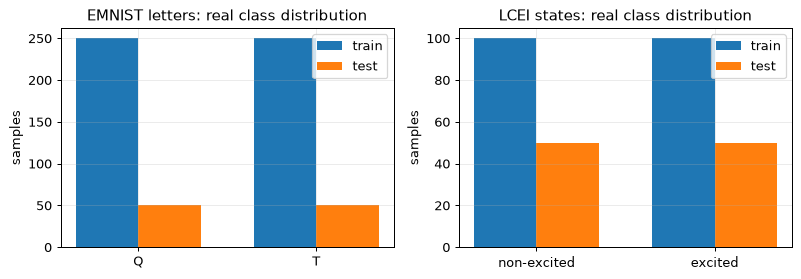

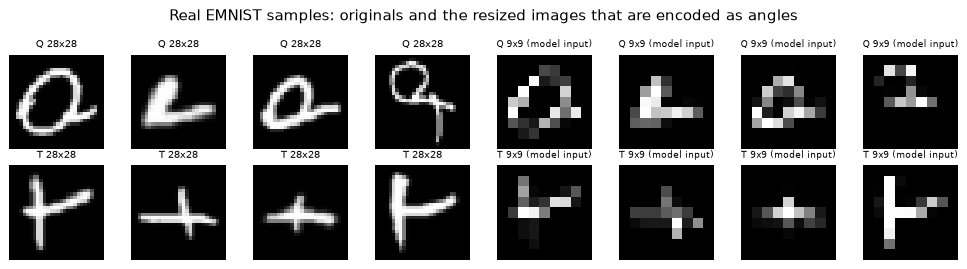

In [8]:
# ---------- EMNIST Q/T: shape, features, labels, counts ----------
em_feat = [f"pixel_{r}_{c}" for r in range(IMG) for c in range(IMG)]
em_names = {0: "Q", 1: "T"}
print("EMNIST letters Q/T  - angle matrix", X_ang.shape, "(samples x pixels), 28x28 originals resized to", (IMG, IMG))
print("  first feature names:", em_feat[:5], "...", em_feat[-2:])
print("  original EMNIST labels: 'Q' (letters index 16/17) -> 0, 'T' (19/20) -> 1; counts all:", {int(k): int(v) for k, v in zip(*np.unique(emnist_y, return_counts=True))})
print("  train counts:", {int(k): int(v) for k, v in zip(*np.unique(em_ytr, return_counts=True))}, "| test counts:", {int(k): int(v) for k, v in zip(*np.unique(em_yte, return_counts=True))})
# ---------- LCEI ----------
lc_feat = [f"alpha_{i}" for i in range(N_QUBITS)]
lc_names = {0: "non-excited (|alpha| < pi/2)", 1: "excited (|alpha| > pi/2)"}
lc_X_all = np.repeat(alpha_all[:, None], N_QUBITS, axis=1)                    # model input: one Rx angle per qubit
print("LCEI synthetic      - input matrix", lc_X_all.shape, "(states x rotation angles); feature names:", lc_feat[:3], "...")
print("  labels: 0 = non-excited, 1 = excited; counts all:", {int(k): int(v) for k, v in zip(*np.unique(lcei_y, return_counts=True))},
      "| train:", {int(k): int(v) for k, v in zip(*np.unique(lcei_y[lc_tr], return_counts=True))}, "| test:", {int(k): int(v) for k, v in zip(*np.unique(lcei_y[lc_te], return_counts=True))})

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
w = 0.35
for a, (title, ytr_, yte_, names) in zip(ax, [("EMNIST letters", em_ytr, em_yte, em_names), ("LCEI states", lcei_y[lc_tr], lcei_y[lc_te], {0: "non-excited", 1: "excited"})]):
    ctr, cte = np.bincount(ytr_, minlength=2), np.bincount(yte_, minlength=2)
    a.bar(np.arange(2) - w / 2, ctr, w, label="train"); a.bar(np.arange(2) + w / 2, cte, w, label="test")
    a.set_xticks([0, 1]); a.set_xticklabels([names[0], names[1]]); a.set_title(f"{title}: real class distribution"); a.set_ylabel("samples"); a.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 8, figsize=(11, 3))
for r, cls in enumerate([0, 1]):
    ids = np.where(emnist_y == cls)[0][:4]
    for c, i in enumerate(ids):
        ax[r, c].imshow(raw_imgs[i], cmap="gray"); ax[r, c].axis("off"); ax[r, c].set_title(f"{em_names[cls]} 28x28", fontsize=8)
        ax[r, c + 4].imshow(small_imgs[i], cmap="gray"); ax[r, c + 4].axis("off"); ax[r, c + 4].set_title(f"{em_names[cls]} {IMG}x{IMG} (model input)", fontsize=7)
plt.suptitle("Real EMNIST samples: originals and the resized images that are encoded as angles"); plt.tight_layout(); plt.show()

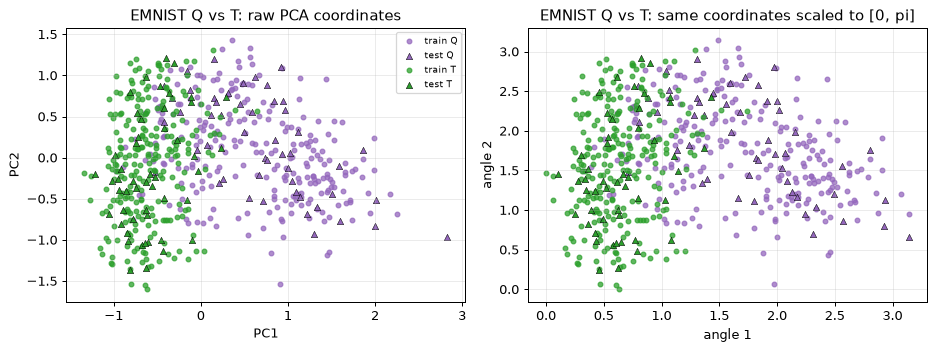

EMNIST PCA explained variance ratio: [0.126 0.075]


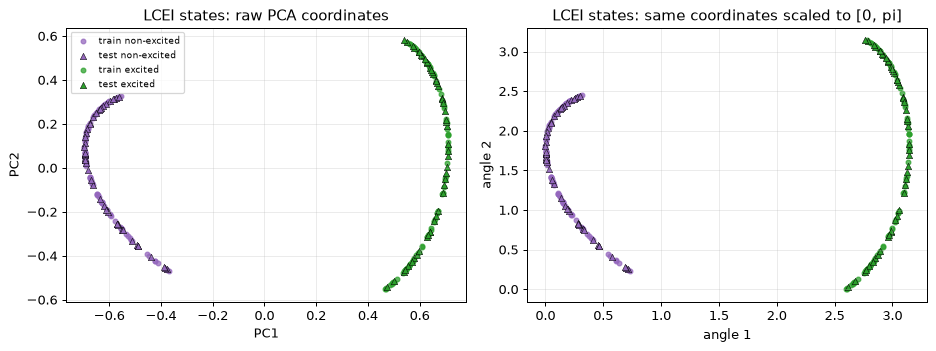

LCEI state PCA explained variance ratio: [0.684 0.187]


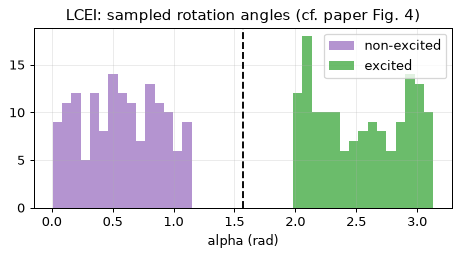

In [9]:
# ---------- 2-D scatter of real observations coloured by ground truth (PCA fitted on the training split only) ----------
def scatter_pair(Ztr, ytr_, Zte, yte_, title, names, scale_to_pi=True):
    cols = {0: "tab:purple", 1: "tab:green"}
    fig, ax = plt.subplots(1, 2 if scale_to_pi else 1, figsize=(10.5 if scale_to_pi else 5, 4))
    ax = np.atleast_1d(ax)
    for c in (0, 1):
        ax[0].scatter(Ztr[ytr_ == c, 0], Ztr[ytr_ == c, 1], s=14, color=cols[c], alpha=.75, label=f"train {names[c]}")
        ax[0].scatter(Zte[yte_ == c, 0], Zte[yte_ == c, 1], s=26, color=cols[c], marker="^", edgecolor="k", linewidth=.4, label=f"test {names[c]}")
    ax[0].set_title(f"{title}: raw PCA coordinates"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend(fontsize=7)
    if scale_to_pi:
        sc = MinMaxScaler((0, np.pi)).fit(Ztr)                      # fitted on the training split only
        Atr, Ate = sc.transform(Ztr), np.clip(sc.transform(Zte), 0, np.pi)
        for c in (0, 1):
            ax[1].scatter(Atr[ytr_ == c, 0], Atr[ytr_ == c, 1], s=14, color=cols[c], alpha=.75, label=f"train {names[c]}")
            ax[1].scatter(Ate[yte_ == c, 0], Ate[yte_ == c, 1], s=26, color=cols[c], marker="^", edgecolor="k", linewidth=.4)
        ax[1].set_title(f"{title}: same coordinates scaled to [0, pi]"); ax[1].set_xlabel("angle 1"); ax[1].set_ylabel("angle 2")
    plt.tight_layout(); plt.show()

# EMNIST: PCA of the 81 pixel angles
pca_em = PCA(2, random_state=SEED).fit(em_Xtr)
scatter_pair(pca_em.transform(em_Xtr), em_ytr, pca_em.transform(em_Xte), em_yte, "EMNIST Q vs T", em_names)
print("EMNIST PCA explained variance ratio:", np.round(pca_em.explained_variance_ratio_, 3))

# LCEI: the real observations are quantum states; project the amplitudes (real and imaginary parts) of the prepared states
with torch.no_grad():
    st_all = cluster_state(torch.tensor(lc_X_all), N_QUBITS).numpy()
feat_states = np.concatenate([st_all.real, st_all.imag], axis=1)           # (300, 2 * 2^n)
pca_lc = PCA(2, random_state=SEED).fit(feat_states[lc_tr])
scatter_pair(pca_lc.transform(feat_states[lc_tr]), lcei_y[lc_tr], pca_lc.transform(feat_states[lc_te]), lcei_y[lc_te], "LCEI states", {0: "non-excited", 1: "excited"})
print("LCEI state PCA explained variance ratio:", np.round(pca_lc.explained_variance_ratio_, 3))
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.hist(alpha_all[lcei_y == 0], bins=15, alpha=.7, color="tab:purple", label="non-excited"); ax.hist(alpha_all[lcei_y == 1], bins=15, alpha=.7, color="tab:green", label="excited")
ax.axvline(np.pi / 2, color="k", ls="--"); ax.set_xlabel("alpha (rad)"); ax.set_title("LCEI: sampled rotation angles (cf. paper Fig. 4)"); ax.legend(); plt.show()

## Quantum Circuit Architecture

Three distinct gate-based architectures are trained or evaluated in this notebook, and every one is drawn below from the **same gate list that the simulator executes**, built as a Qiskit `QuantumCircuit` and *asserted equal* to the engine (output expectation `<Z>` agrees to `1e-10` for random parameters and inputs):

1. the 8-qubit **EMNIST QNN** (`Rx(pi/2)` initial layer, then SU(2)+CZ blocks with data re-uploading `phi = x + theta`);
2. the 8-qubit **LCEI QNN** (cluster-state preparation `H, CZ-chain, Rx(alpha_i)` followed by the same variational body, all parameters variational);
3. the 6-qubit **LCEI QNN used for the noise study** (same family, narrower);
4. the 3-qubit **data re-uploading QNN** of the matched-size Table I study (drawn for `Nr = 1`; larger `Nr` repeats the same block).

Assumptions where the paper omits circuit details (all in the table of choices above): the number of CZ layers per block, the repetition `REPEAT`, which `Rz` receives which pixel, the initial `Rx(pi/2)` layer, the output-qubit index. Qubit count, depth and trainable-parameter count are printed for every circuit; the paper-scale count (181) was verified in the previous cell.

EMNIST QNN: qubits=8, depth=74, trainable parameters=181, data inputs=81, gate counts={'rz': 180, 'rx': 129, 'cz': 26, 'barrier': 13, 'measure': 1}


  engine == Qiskit Statevector: max |difference| = 6.5e-15  (assertion passed)


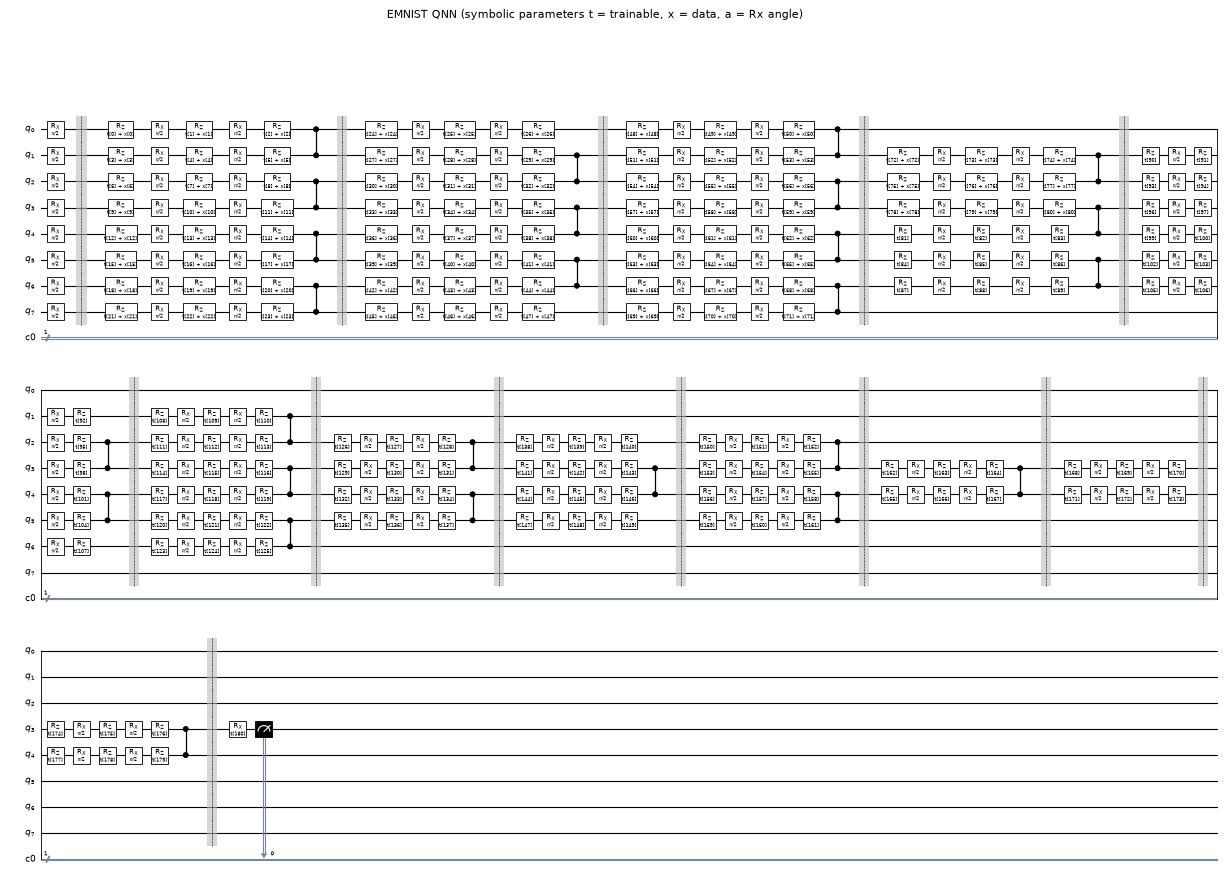

In [10]:
def check_and_draw(spec, name, with_alpha=False, fold=45):
    """Build symbolic circuit, draw it, and assert equality with the PyTorch engine on random numeric inputs."""
    th_p = ParameterVector("t", spec.npar)
    x_p = ParameterVector("x", spec.n_enc) if spec.n_enc else None
    a_p = ParameterVector("a", spec.n) if with_alpha else None
    qc_sym = qiskit_qnn(spec, th_p, x_p, a_p)
    qc_sym.add_register(ClassicalRegister(1)); qc_sym.measure(spec.out, 0)          # only the output qubit is read out
    print(f"{name}: qubits={qc_sym.num_qubits}, depth={qc_sym.depth()}, trainable parameters={spec.npar}, "
          f"data inputs={spec.n_enc if not with_alpha else spec.n}, gate counts={dict(qc_sym.count_ops())}")
    g = np.random.default_rng(1)
    worst = 0.0
    for _ in range(3):
        th = g.uniform(-np.pi, np.pi, spec.npar)
        if with_alpha:
            al = g.uniform(0, np.pi, spec.n)
            qc = qiskit_qnn(spec, th, None, al)
            z_eng = float(run_qnn(spec, torch.tensor(th), state=cluster_state(torch.tensor(al)[None], spec.n))[0])
        else:
            xv = g.uniform(0, 1, spec.n_enc)
            qc = qiskit_qnn(spec, th, xv)
            z_eng = float(run_qnn(spec, torch.tensor(th), x=torch.tensor(xv)[None])[0])
        worst = max(worst, abs(z_eng - qiskit_z(qc, spec.n, spec.out)))
    assert worst < 1e-10, worst
    print(f"  engine == Qiskit Statevector: max |difference| = {worst:.1e}  (assertion passed)")
    fig = qc_sym.draw("mpl", fold=fold, scale=0.45, style="bw")
    fig.suptitle(f"{name} (symbolic parameters t = trainable, x = data, a = Rx angle)", fontsize=9)
    display(fig); plt.close(fig)                      # the Qiskit figure is not a pyplot figure: display it explicitly

check_and_draw(SPEC_EM, "EMNIST QNN")

LCEI QNN (8 qubits): qubits=8, depth=82, trainable parameters=181, data inputs=8, gate counts={'rz': 180, 'rx': 129, 'cz': 33, 'barrier': 13, 'h': 8, 'measure': 1}


  engine == Qiskit Statevector: max |difference| = 3.4e-15  (assertion passed)


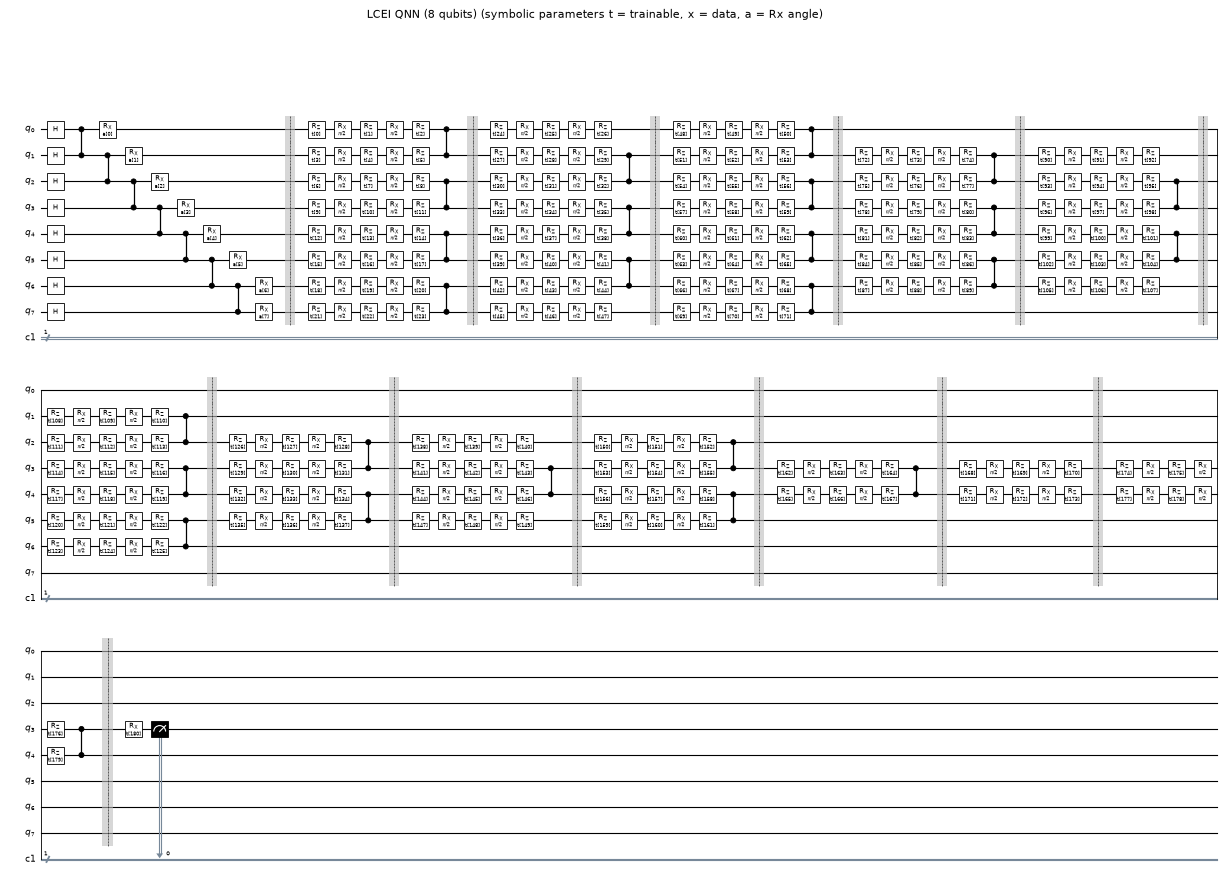

LCEI noise-study QNN: 6 qubits, block widths [6, 6, 6, 4, 4, 4, 2, 2, 2], 108 Rz slots (0 data-carrying, 108 variational) + 1 final Rx = 109 trainable parameters, output qubit 2
LCEI QNN (6 qubits, noise study): qubits=6, depth=62, trainable parameters=109, data inputs=6, gate counts={'rz': 108, 'rx': 79, 'cz': 20, 'barrier': 10, 'h': 6, 'measure': 1}


  engine == Qiskit Statevector: max |difference| = 7.2e-15  (assertion passed)


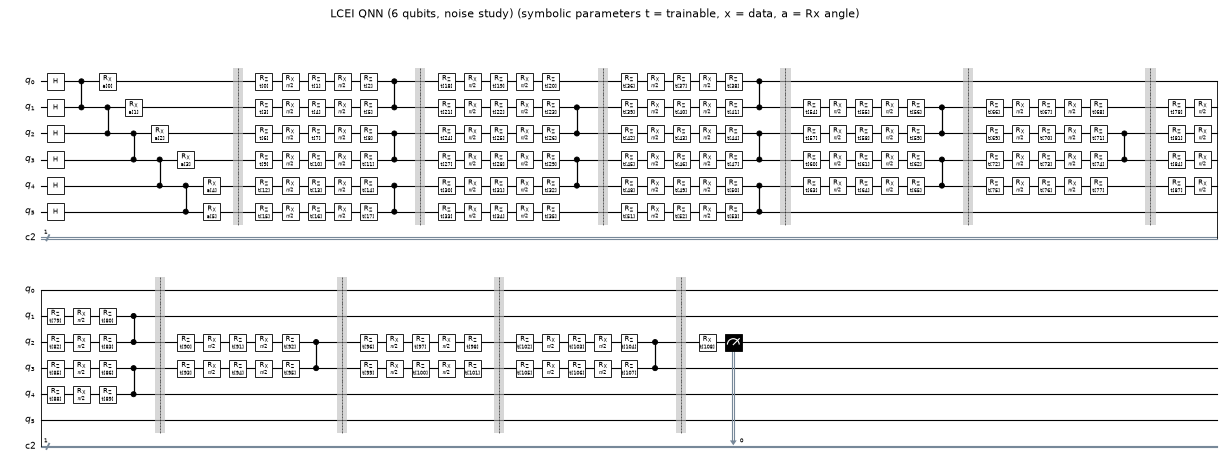

In [11]:
check_and_draw(SPEC_LC, f"LCEI QNN ({N_QUBITS} qubits)", with_alpha=True)
SPEC_NZ = QNNSpec(NOISE_QUBITS, B=NOISE_BLOCKS, cut=CUT, n_enc=0, prep=False, rep=REPEAT)
print("LCEI noise-study QNN:", SPEC_NZ.summary())
check_and_draw(SPEC_NZ, "LCEI QNN (6 qubits, noise study)", with_alpha=True)

re-uploading QNN (Nr=1): qubits=3, depth=45, trainable parameters=162 (w and b per data gate), gate counts={'ry': 54, 'rz': 27, 'cz': 18, 'measure': 1}
  engine == Qiskit Statevector for the re-uploading circuit (assertion passed)


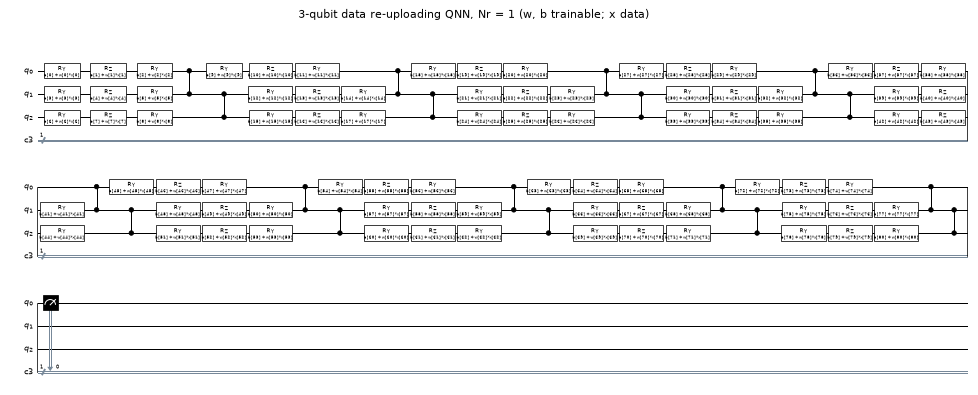

In [12]:
# 4th architecture: the 3-qubit data re-uploading QNN of Table I (Nr = 1), symbolic drawing + equivalence check with the engine
RT = ReuploadTask(1, 0.05, 25, 1, MASK_R_EMNIST)
w_p, b_p, x_p = ParameterVector("w", RT.G), ParameterVector("b", RT.G), ParameterVector("x", RT.nin)
qc_ru = qiskit_reupload(1, w_p, b_p, x_p); qc_ru.add_register(ClassicalRegister(1)); qc_ru.measure(0, 0)
print(f"re-uploading QNN (Nr=1): qubits={qc_ru.num_qubits}, depth={qc_ru.depth()}, trainable parameters={RT.npar} (w and b per data gate), gate counts={dict(qc_ru.count_ops())}")
g = np.random.default_rng(3); thr = g.normal(1, .3, RT.npar); xr = g.uniform(0, 1, RT.nin)
qc_num = qiskit_reupload(1, thr[:RT.G], thr[RT.G:], xr)
z_eng = float(RT.forward(torch.tensor(thr), torch.tensor(xr)[None])[0])
assert abs(z_eng - qiskit_z(qc_num, 3, 0)) < 1e-10
print("  engine == Qiskit Statevector for the re-uploading circuit (assertion passed)")
fig = qc_ru.draw("mpl", fold=40, scale=0.4, style="bw"); fig.suptitle("3-qubit data re-uploading QNN, Nr = 1 (w, b trainable; x data)", fontsize=9); display(fig); plt.close(fig)

## 3. Classical baselines on identical inputs

Before any quantum training, the two standard classical baselines are fitted on **exactly the same inputs** the QNN sees: the 81 pixel angles (EMNIST) and the `n` rotation angles (LCEI, all equal, so the task is a one-dimensional threshold). They show how hard the tasks are and give the reference accuracy for the QNN. A `RandomForestClassifier` and an RBF `SVC`; both use the training split only.

In [13]:
t_em = lambda a: torch.tensor(np.asarray(a), dtype=torch.float64)
t_lb = lambda a: torch.tensor(np.asarray(a), dtype=torch.float64)
EM_Xtr, EM_Xte, EM_ytr, EM_yte = t_em(em_Xtr), t_em(em_Xte), t_lb(em_ytr), t_lb(em_yte)
LC_X_all = t_em(lc_X_all)
LC_Xtr, LC_Xte, LC_ytr, LC_yte = LC_X_all[lc_tr], LC_X_all[lc_te], t_lb(lcei_y[lc_tr]), t_lb(lcei_y[lc_te])

baselines = {}
for name, (Xtr_, ytr_, Xte_, yte_) in {"EMNIST": (em_Xtr, em_ytr, em_Xte, em_yte), "LCEI": (lc_X_all[lc_tr], lcei_y[lc_tr], lc_X_all[lc_te], lcei_y[lc_te])}.items():
    for mname, model in (("RandomForest", RandomForestClassifier(n_estimators=300, random_state=SEED)), ("SVC-rbf", SVC(kernel="rbf", C=1.0, gamma="scale"))):
        t0 = time.time(); model.fit(Xtr_, ytr_); dt = time.time() - t0
        baselines[(name, mname)] = dict(model=model, train=model.score(Xtr_, ytr_), test=model.score(Xte_, yte_), time=dt)
        cm = confusion_matrix(yte_, model.predict(Xte_))
        print(f"{name:7s} {mname:12s} train acc {baselines[(name, mname)]['train']:.3f}  test acc {baselines[(name, mname)]['test']:.3f}  fit {dt:.2f}s  confusion (rows true 0/1, attack/positive = class 1) {cm.tolist()}")

EMNIST  RandomForest train acc 1.000  test acc 0.960  fit 2.97s  confusion (rows true 0/1, attack/positive = class 1) [[49, 1], [3, 47]]
EMNIST  SVC-rbf      train acc 0.986  test acc 0.990  fit 0.07s  confusion (rows true 0/1, attack/positive = class 1) [[49, 1], [0, 50]]


LCEI    RandomForest train acc 1.000  test acc 1.000  fit 2.86s  confusion (rows true 0/1, attack/positive = class 1) [[50, 0], [0, 50]]
LCEI    SVC-rbf      train acc 1.000  test acc 1.000  fit 0.01s  confusion (rows true 0/1, attack/positive = class 1) [[50, 0], [0, 50]]


## 4. Training the QNNs (clean training)

Training follows the paper: mini-batch Adam (`beta = (0.9, 0.999)`), cross-entropy on `p = (<Z> + 1)/2`, exact gradients (back-propagation through the simulator replaces the parameter-shift rule used on the chip; both are exact for this gate set). Parameters start at `theta ~ U(-pi, pi)` (`# CHOICE:`). The same initial parameters are re-used later for adversarial training so that the two models differ only by the training data.

In [14]:
def accuracy(task, theta, X, y):
    z = task.z(theta, X)
    return float(((z > 0).long() == y.long()).double().mean())

def train_qnn(task, theta0, Xtr, ytr, Xte, yte, epochs, adv=None, seed=SEED, tag="", every=1):
    """Mini-batch Adam. adv=(Xadv, yadv): every mini-batch is 50 % legitimate + 50 % adversarial samples (paper, Eq. 9)."""
    theta = theta0.clone().requires_grad_(True)
    opt = torch.optim.Adam([theta], lr=task.lr, betas=(0.9, 0.999))
    g = np.random.default_rng(seed)
    rows, t0 = [], time.time()
    for ep in range(1, epochs + 1):
        perm = g.permutation(len(Xtr)); ls, ac = [], []
        for i in range(0, len(perm), task.bs):
            idx = perm[i:i + task.bs]
            xb, yb = Xtr[idx], ytr[idx]
            if adv is not None:
                half = max(1, len(idx) // 2)
                ia = g.choice(len(adv[0]), len(idx) - half, replace=False)
                xb = torch.cat([Xtr[idx[:half]], adv[0][ia]]); yb = torch.cat([ytr[idx[:half]], adv[1][ia]])
            z = task.forward(theta, xb)[0]
            loss = ce_loss(z, yb)
            opt.zero_grad(); loss.backward(); opt.step()
            ls.append(float(loss)); ac.append(float(((z > 0).long() == yb.long()).double().mean()))
        th = theta.detach()
        row = dict(epoch=ep, loss=np.mean(ls), train_acc_minibatch=np.mean(ac), test_acc=accuracy(task, th, Xte, yte))
        if adv is not None: row["adv_acc"] = accuracy(task, th, adv[0], adv[1])
        rows.append(row)
        if ep % every == 0 or ep == epochs:
            print(f"[{tag}] epoch {ep:3d}/{epochs}  loss {row['loss']:.3f}  mini-batch acc {row['train_acc_minibatch']:.3f}  test acc {row['test_acc']:.3f}"
                  + (f"  adv acc {row['adv_acc']:.3f}" if adv is not None else "") + f"  ({time.time() - t0:.0f}s)")
    return theta.detach(), pd.DataFrame(rows)

In [15]:
g0 = np.random.default_rng(SEED)
THETA0_EM = torch.tensor(g0.uniform(-np.pi, np.pi, SPEC_EM.npar))
THETA0_LC = torch.tensor(g0.uniform(-np.pi, np.pi, SPEC_LC.npar))

t0 = time.time()
th_em_clean, hist_em_clean = train_qnn(TASK_EM, THETA0_EM, EM_Xtr, EM_ytr, EM_Xte, EM_yte, TASK_EM.epochs, tag="EMNIST clean", every=max(1, TASK_EM.epochs // 8))
th_lc_clean, hist_lc_clean = train_qnn(TASK_LC, THETA0_LC, LC_Xtr, LC_ytr, LC_Xte, LC_yte, TASK_LC.epochs, tag="LCEI clean", every=max(1, TASK_LC.epochs // 6))
TRAIN_TIME = time.time() - t0

[EMNIST clean] epoch   5/40  loss 0.455  mini-batch acc 0.836  test acc 0.830  (28s)


[EMNIST clean] epoch  10/40  loss 0.413  mini-batch acc 0.858  test acc 0.910  (55s)


[EMNIST clean] epoch  15/40  loss 0.395  mini-batch acc 0.858  test acc 0.890  (81s)


[EMNIST clean] epoch  20/40  loss 0.398  mini-batch acc 0.862  test acc 0.890  (114s)


[EMNIST clean] epoch  25/40  loss 0.400  mini-batch acc 0.872  test acc 0.910  (143s)


...

[LCEI clean] epoch  12/25  loss 0.068  mini-batch acc 1.000  test acc 1.000  (41s)


[LCEI clean] epoch  16/25  loss 0.055  mini-batch acc 1.000  test acc 1.000  (56s)


[LCEI clean] epoch  20/25  loss 0.048  mini-batch acc 1.000  test acc 1.000  (69s)


[LCEI clean] epoch  24/25  loss 0.042  mini-batch acc 1.000  test acc 1.000  (83s)


[LCEI clean] epoch  25/25  loss 0.040  mini-batch acc 1.000  test acc 1.000  (89s)


EMNIST Q/T: test confusion matrix (rows true 0/1; columns predicted 0/1; class 1 = positive) = [[45, 5], [6, 44]]


LCEI: test confusion matrix (rows true 0/1; columns predicted 0/1; class 1 = positive) = [[50, 0], [0, 50]]
      task  train_acc  test_acc  test_precision  test_recall  test_f1
EMNIST Q/T      0.888      0.89           0.898         0.88    0.889
      LCEI      1.000      1.00           1.000         1.00    1.000


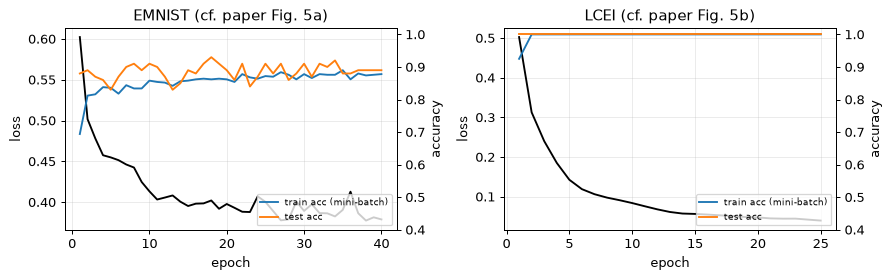

In [16]:
def full_metrics(task, theta, X, y):
    z = task.z(theta, X); pred = (z > 0).long().numpy(); yy = y.long().numpy()
    tp = int(((pred == 1) & (yy == 1)).sum()); fp = int(((pred == 1) & (yy == 0)).sum()); fn = int(((pred == 0) & (yy == 1)).sum())
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    return dict(acc=float((pred == yy).mean()), precision=prec, recall=rec, f1=2 * prec * rec / max(prec + rec, 1e-12), cm=confusion_matrix(yy, pred, labels=[0, 1]))

clean_rows = []
for task, th, Xtr_, ytr_, Xte_, yte_ in ((TASK_EM, th_em_clean, EM_Xtr, EM_ytr, EM_Xte, EM_yte), (TASK_LC, th_lc_clean, LC_Xtr, LC_ytr, LC_Xte, LC_yte)):
    mtr, mte = full_metrics(task, th, Xtr_, ytr_), full_metrics(task, th, Xte_, yte_)
    clean_rows.append(dict(task=task.name, train_acc=mtr["acc"], test_acc=mte["acc"], test_precision=mte["precision"], test_recall=mte["recall"], test_f1=mte["f1"]))
    print(f"{task.name}: test confusion matrix (rows true 0/1; columns predicted 0/1; class 1 = positive) = {mte['cm'].tolist()}")
print(pd.DataFrame(clean_rows).round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for a, h, ttl in ((ax[0], hist_em_clean, "EMNIST (cf. paper Fig. 5a)"), (ax[1], hist_lc_clean, "LCEI (cf. paper Fig. 5b)")):
    a.plot(h.epoch, h.loss, label="loss", color="k"); a.set_xlabel("epoch"); a.set_ylabel("loss"); b = a.twinx(); b.grid(False)
    b.plot(h.epoch, h.train_acc_minibatch, color="tab:blue", label="train acc (mini-batch)"); b.plot(h.epoch, h.test_acc, color="tab:orange", label="test acc")
    b.set_ylim(0.4, 1.02); b.set_ylabel("accuracy"); a.set_title(ttl); b.legend(loc="lower right", fontsize=7)
plt.tight_layout(); plt.show()

## 5. Mask-FGSM: gradient mask, attack, accuracy under attack

**Algorithm 1/2 of the paper.** (1) average the absolute input gradient `G = mean_i |grad_x L(x_i)|` over a small calibration batch (20 test samples); (2) keep the top `r * dim(x)` coordinates as a binary mask `M`; (3) perturb only those coordinates, `x' = x + eps * (M * sign(grad_x L))` with `eps = eps_hat * (x_max - x_min)`. The paper obtains the gradient on the chip by the parameter-shift rule with shots; here the simulator gives the exact gradient (so this is the *noise-free* attack). For EMNIST the coordinates are pixels, for LCEI they are the `n` rotation angles of the `Rx(alpha_i)` gates (Algorithm 2).

EMNIST mask: 12/81 pixels (r = 0.15), captures 42 % of the L1 gradient mass (paper: >= 90 %)
LCEI   mask: angles [3, 4, 5] of 8 (r = 0.4), captures 59 % of the L1 gradient mass (paper: qubits Q7-Q14 of 20)


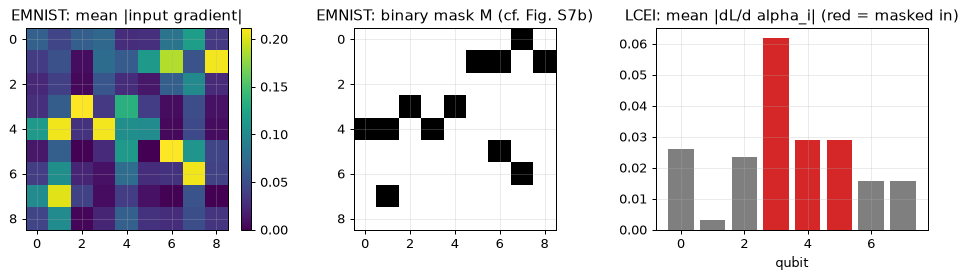

In [17]:
def input_gradient(task, theta, X, y):
    """Per-sample gradient of the cross-entropy loss with respect to the input angles."""
    Xg = X.clone().requires_grad_(True)
    z = task.forward(theta, Xg)[0]
    p = ((1 + z) / 2).clamp(1e-7, 1 - 1e-7)
    L = -(y * torch.log(p) + (1 - y) * torch.log(1 - p))
    L.sum().backward()
    return Xg.grad.detach()

def build_mask(G, r):
    gbar = G.abs().mean(0)
    k = max(1, int(round(r * gbar.numel())))
    M = torch.zeros_like(gbar); M[torch.topk(gbar, k).indices] = 1.0
    frac = float(gbar[M.bool()].sum() / gbar.sum())
    return M, frac, gbar

def mask_fgsm(X, G, M, eps_hat, xrange):
    """Eq. (1): x' = x + eps * (M * sign(grad)),  eps = eps_hat * (x_max - x_min)."""
    return X + eps_hat * xrange * M * torch.sign(G)

def calib_indices(y, n=N_MASK_SAMPLES, seed=SEED):
    g = np.random.default_rng(seed); yy = y.long().numpy()
    return np.r_[g.choice(np.where(yy == 0)[0], n // 2, replace=False), g.choice(np.where(yy == 1)[0], n // 2, replace=False)]

def make_mask(task, theta, X, y):
    ci = calib_indices(y)
    G = input_gradient(task, theta, X[ci], y[ci])
    return build_mask(G, task.mask_r)

def attack_curve(task, theta, X, y, M, grid):
    G = input_gradient(task, theta, X, y)
    return np.array([accuracy(task, theta, mask_fgsm(X, G, M, e, task.xrange), y) for e in grid])

# masks of the clean models (calibration: 20 test samples, as in the paper)
M_em, frac_em, gbar_em = make_mask(TASK_EM, th_em_clean, EM_Xte, EM_yte)
M_lc, frac_lc, gbar_lc = make_mask(TASK_LC, th_lc_clean, LC_Xte, LC_yte)
print(f"EMNIST mask: {int(M_em.sum())}/{M_em.numel()} pixels (r = {TASK_EM.mask_r}), captures {100 * frac_em:.0f} % of the L1 gradient mass (paper: >= 90 %)")
print(f"LCEI   mask: angles {np.where(M_lc.numpy() > 0)[0].tolist()} of {M_lc.numel()} (r = {TASK_LC.mask_r}), captures {100 * frac_lc:.0f} % of the L1 gradient mass (paper: qubits Q7-Q14 of 20)")

fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
im = ax[0].imshow(gbar_em.reshape(IMG, IMG), cmap="viridis"); ax[0].set_title("EMNIST: mean |input gradient|"); plt.colorbar(im, ax=ax[0], fraction=.046)
ax[1].imshow(M_em.reshape(IMG, IMG), cmap="gray_r"); ax[1].set_title("EMNIST: binary mask M (cf. Fig. S7b)")
ax[2].bar(range(N_QUBITS), gbar_lc.numpy(), color=["tab:red" if m else "tab:gray" for m in M_lc.numpy()]); ax[2].set_title("LCEI: mean |dL/d alpha_i| (red = masked in)"); ax[2].set_xlabel("qubit")
plt.tight_layout(); plt.show()

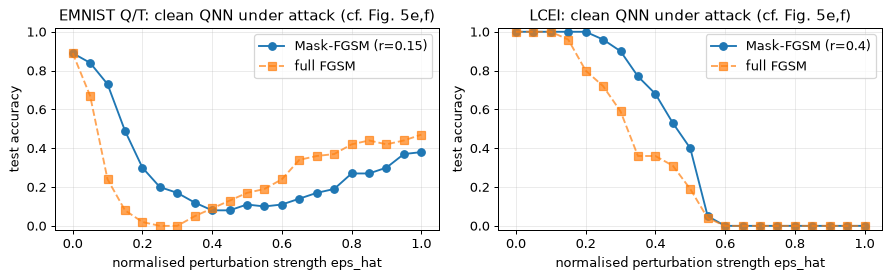

EMNIST Q/T: accuracy at eps_hat = 0 / 0.2 / 0.5 / 1.0 : Mask-FGSM 0.89 / 0.30 / 0.11 / 0.38   full FGSM 0.89 / 0.02 / 0.17 / 0.47
LCEI: accuracy at eps_hat = 0 / 0.2 / 0.5 / 1.0 : Mask-FGSM 1.00 / 1.00 / 0.40 / 0.00   full FGSM 1.00 / 0.80 / 0.19 / 0.00


In [18]:
EPS_ACC = np.round(np.arange(0.0, 1.0001, 0.05), 3)               # eps_hat grid for accuracy-under-attack curves
acc_curve = {}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for a, task, th, M, Xte_, yte_, Xtr_, ytr_ in ((ax[0], TASK_EM, th_em_clean, M_em, EM_Xte, EM_yte, EM_Xtr, EM_ytr), (ax[1], TASK_LC, th_lc_clean, M_lc, LC_Xte, LC_yte, LC_Xtr, LC_ytr)):
    ca = attack_curve(task, th, Xte_, yte_, M, EPS_ACC)
    # full (unmasked) FGSM for reference: same step, every coordinate perturbed
    G = input_gradient(task, th, Xte_, yte_)
    cf = np.array([accuracy(task, th, mask_fgsm(Xte_, G, torch.ones_like(M), e, task.xrange), yte_) for e in EPS_ACC])
    acc_curve[task.name] = (ca, cf)
    a.plot(EPS_ACC, ca, "o-", label=f"Mask-FGSM (r={task.mask_r})"); a.plot(EPS_ACC, cf, "s--", label="full FGSM", alpha=.7)
    a.set_xlabel("normalised perturbation strength eps_hat"); a.set_ylabel("test accuracy"); a.set_title(f"{task.name}: clean QNN under attack (cf. Fig. 5e,f)"); a.legend(); a.set_ylim(-0.02, 1.02)
plt.tight_layout(); plt.show()
for n_, (ca, cf) in acc_curve.items():
    print(f"{n_}: accuracy at eps_hat = 0 / 0.2 / 0.5 / 1.0 : Mask-FGSM {ca[0]:.2f} / {ca[4]:.2f} / {ca[10]:.2f} / {ca[20]:.2f}   full FGSM {cf[0]:.2f} / {cf[4]:.2f} / {cf[10]:.2f} / {cf[20]:.2f}")

## 6. Robustness bounds: analytic lower bound vs attack-derived upper bound (paper Fig. 2)

For one input the robustness radius is measured in **state infidelity** `D(rho, sigma) = 1 - F(rho, sigma)` between the output-qubit states of the legitimate and the perturbed input. Eq. (2) gives a certified lower bound from the clean prediction alone, `R_LB = (1/2)(sqrt(p1) - sqrt(p2))^2`. An attack gives an upper bound: along the Mask-FGSM direction the prediction first flips at `eps_hat*` (where `p = 0.5`), and the infidelity there is `R_UB`. By construction `R_UB >= R_LB`; the paper measures the gap on hardware (`2.96e-3` EMNIST, `3.25e-3` LCEI, mean over ten samples). With the exact simulator the output-qubit state is known without tomography, `eps_hat*` is found by bisection (no cos^2 fit), and the single-qubit fidelity is `F = (1 + r.s + sqrt((1-r^2)(1-s^2)))/2` from the two Bloch vectors.

In [19]:
def infidelity(r, s):
    """D = 1 - F for single-qubit states with Bloch vectors r, s (rows)."""
    rs = (r * s).sum(1)
    F = 0.5 * (1 + rs + torch.sqrt(((1 - (r * r).sum(1)).clamp(min=0)) * ((1 - (s * s).sum(1)).clamp(min=0))))
    return (1 - F).clamp(min=0)

def bounds_experiment(task, theta, X, y, M, per_class=N_BOUND_SAMPLES // 2, eps_max=2.0, ngrid=200):
    z0 = task.z(theta, X); ok = ((z0 > 0).long() == y.long())
    sel = np.r_[np.where((y == 0).numpy() & ok.numpy())[0][:per_class], np.where((y == 1).numpy() & ok.numpy())[0][:per_class]]
    Xs, ys = X[sel], y[sel]; s = 2 * ys - 1                                    # +1 for class 1, -1 for class 0
    G = input_gradient(task, theta, Xs, ys)
    d = task.xrange * M * torch.sign(G)                                         # direction per unit eps_hat
    def margin(e):                                                              # e: (B,) -> s*z  (>0 correct)
        z, st = task.forward(theta, Xs + e[:, None] * d)
        return (s * z).detach(), st
    grid = torch.linspace(0, eps_max, ngrid, dtype=torch.float64)
    marg = torch.stack([margin(torch.full((len(sel),), float(e), dtype=torch.float64))[0] for e in grid], 1)   # (B, E)
    crossed = (marg <= 0).any(1)
    first = torch.where(crossed, (marg <= 0).float().argmax(1), torch.zeros(len(sel), dtype=torch.long))
    lo = grid[(first - 1).clamp(min=0)].clone(); hi = grid[first].clone()
    for _ in range(45):                                                          # bisection for the exact crossing (z = 0, i.e. p = 0.5)
        mid = 0.5 * (lo + hi); m, _ = margin(mid)
        lo = torch.where(m > 0, mid, lo); hi = torch.where(m > 0, hi, mid)
    eps_star = 0.5 * (lo + hi)
    with torch.no_grad():
        z_c, st_c = task.forward(theta, Xs); _, st_a = task.forward(theta, Xs + hi[:, None] * d)
        D = infidelity(out_bloch(st_c, task.spec.out), out_bloch(st_a, task.spec.out))
    p = (1 + z_c) / 2; p1 = torch.maximum(p, 1 - p); p2 = 1 - p1
    R_LB = 0.5 * (torch.sqrt(p1) - torch.sqrt(p2)) ** 2
    df = pd.DataFrame(dict(sample=sel, label=ys.long().numpy(), p=p.numpy(), eps_star=eps_star.numpy(), R_LB=R_LB.numpy(), R_UB=D.numpy(), crossed=crossed.numpy()))
    df["gap"] = df.R_UB - df.R_LB
    return df, (Xs, ys, d, grid)

bnd = {}
for task, th, M, Xte_, yte_ in ((TASK_EM, th_em_clean, M_em, EM_Xte, EM_yte), (TASK_LC, th_lc_clean, M_lc, LC_Xte, LC_yte)):
    df, aux = bounds_experiment(task, th, Xte_, yte_, M)
    bnd[task.name] = (df, aux)
    ok = df[df.crossed]
    print(f"\n{task.name}: {len(ok)}/{len(df)} samples flipped by Mask-FGSM within eps_hat <= 2")
    print(ok[["sample", "label", "p", "eps_star", "R_LB", "R_UB", "gap"]].round(5).to_string(index=False))
    if len(ok):
        assert (ok.R_UB >= ok.R_LB - 1e-9).all(), "R_UB < R_LB would contradict the certified lower bound"
        print(f"  mean R_LB = {ok.R_LB.mean():.4f}, mean R_UB = {ok.R_UB.mean():.4f}, mean gap Delta = {ok.gap.mean():.2e}, median gap = {ok.gap.median():.2e}   (paper hardware: {'2.96e-3' if task.name.startswith('EMNIST') else '3.25e-3'})")


EMNIST Q/T: 10/10 samples flipped by Mask-FGSM within eps_hat <= 2
 sample  label       p  eps_star    R_LB    R_UB     gap
      1      0 0.17154   0.20850 0.12302 0.12434 0.00132
      2      0 0.36786   0.12512 0.01778 0.01940 0.00163
      3      0 0.31755   0.12418 0.03447 0.03472 0.00025
      9      0 0.30161   0.10490 0.04104 0.04127 0.00022
     10      0 0.15601   0.19418 0.13714 0.14327 0.00613
      0      1 0.76611   0.16823 0.07670 0.08459 0.00790
      4      1 0.67289   0.08659 0.03084 0.03097 0.00013
      5      1 0.87584   0.32596 0.17024 0.17112 0.00088
      6      1 0.81559   0.18594 0.11218 0.11406 0.00187
      7      1 0.82192   0.15743 0.11742 0.12368 0.00626
  mean R_LB = 0.0861, mean R_UB = 0.0887, mean gap Delta = 2.66e-03, median gap = 1.47e-03   (paper hardware: 2.96e-3)



LCEI: 10/10 samples flipped by Mask-FGSM within eps_hat <= 2
 sample  label       p  eps_star    R_LB    R_UB     gap
      1      0 0.01150   0.47829 0.39340 0.39450 0.00110
      6      0 0.05840   0.31484 0.26550 0.26940 0.00390
      7      0 0.01235   0.41872 0.38957 0.39301 0.00343
      8      0 0.03791   0.34485 0.30901 0.31301 0.00400
     12      0 0.18019   0.20342 0.11566 0.11794 0.00228
      0      1 0.97819   0.54588 0.35393 0.36349 0.00957
      2      1 0.98107   0.54529 0.36373 0.37526 0.01153
      3      1 0.89994   0.29979 0.19992 0.20026 0.00033
      4      1 0.92107   0.32544 0.23037 0.23059 0.00022
      5      1 0.97915   0.54547 0.35713 0.36711 0.00998
  mean R_LB = 0.2978, mean R_UB = 0.3025, mean gap Delta = 4.63e-03, median gap = 3.67e-03   (paper hardware: 3.25e-3)


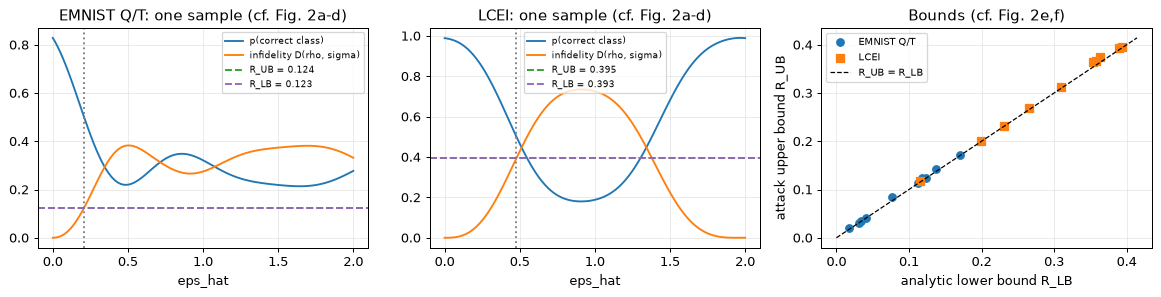

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a, nm in zip(ax[:2], ("EMNIST Q/T", "LCEI")):
    task = TASK_EM if nm.startswith("EMNIST") else TASK_LC
    th = th_em_clean if nm.startswith("EMNIST") else th_lc_clean
    df, (Xs, ys, d, grid) = bnd[nm]
    i = int(np.where(df.crossed.values)[0][0]) if df.crossed.any() else 0
    eg = torch.linspace(0, min(2.0, 2.0), 120, dtype=torch.float64)
    with torch.no_grad():
        z_c, st_c = task.forward(th, Xs[i:i + 1]); zs, sts = task.forward(th, Xs[i:i + 1] + eg[:, None] * d[i:i + 1])
        D = infidelity(out_bloch(st_c, task.spec.out).expand(len(eg), 3), out_bloch(sts, task.spec.out))
    p = (1 + zs) / 2 if ys[i] == 1 else 1 - (1 + zs) / 2
    a.plot(eg, p, label="p(correct class)"); a.plot(eg, D, label="infidelity D(rho, sigma)")
    a.axvline(df.eps_star[i], color="gray", ls=":"); a.axhline(df.R_UB[i], color="tab:green", ls="--", label=f"R_UB = {df.R_UB[i]:.3f}"); a.axhline(df.R_LB[i], color="tab:purple", ls="--", label=f"R_LB = {df.R_LB[i]:.3f}")
    a.set_xlabel("eps_hat"); a.set_title(f"{nm}: one sample (cf. Fig. 2a-d)"); a.legend(fontsize=7)
for nm, mk in (("EMNIST Q/T", "o"), ("LCEI", "s")):
    df = bnd[nm][0]; df = df[df.crossed]
    ax[2].scatter(df.R_LB, df.R_UB, marker=mk, label=nm)
mx = max(bnd[n][0].R_UB.max() for n in bnd) * 1.05
ax[2].plot([0, mx], [0, mx], "k--", lw=1, label="R_UB = R_LB"); ax[2].set_xlabel("analytic lower bound R_LB"); ax[2].set_ylabel("attack upper bound R_UB"); ax[2].set_title("Bounds (cf. Fig. 2e,f)"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Adversarial training

**Paper.** 200 Mask-FGSM samples (100 per class) are generated once from the trained clean model; during adversarial training every mini-batch is 50 % legitimate samples drawn from the training set and 50 % adversarial samples from that set (Eq. 9; the loss is `J = E[ L(x) / 2 + L(x + delta) / 2 ]`). All hyper-parameters equal those of clean training. Which attack strength `eps_hat` generates the 200 samples is not stated; here it is the smallest value in a grid for which the clean model keeps at most 25 % accuracy on them (`# CHOICE:`). Adversarial training starts from the *same* initial parameters as clean training.

In [21]:
def adv_set(task, theta, Xtr, ytr, M, per_class=ADV_PER_CLASS, seed=SEED):
    g = np.random.default_rng(seed); yy = ytr.long().numpy()
    sel = np.r_[g.choice(np.where(yy == 0)[0], min(per_class, (yy == 0).sum()), replace=False), g.choice(np.where(yy == 1)[0], min(per_class, (yy == 1).sum()), replace=False)]
    Xs, ys = Xtr[sel], ytr[sel]
    G = input_gradient(task, theta, Xs, ys)
    rows = [(e, accuracy(task, theta, mask_fgsm(Xs, G, M, e, task.xrange), ys)) for e in EPS_TRAIN_GRID]
    eps = next((e for e, a in rows if a <= 0.25), rows[-1][0])                  # CHOICE: smallest eps_hat with <= 25 % clean-model accuracy
    return mask_fgsm(Xs, G, M, eps, task.xrange), ys, eps, rows

ADV = {}
for task, th, Xtr_, ytr_, M in ((TASK_EM, th_em_clean, EM_Xtr, EM_ytr, M_em), (TASK_LC, th_lc_clean, LC_Xtr, LC_ytr, M_lc)):
    Xa, ya, eps, rows = adv_set(task, th, Xtr_, ytr_, M)
    ADV[task.name] = (Xa, ya, eps)
    print(f"{task.name}: clean-model accuracy on the generated adversarial training samples vs eps_hat: " + ", ".join(f"{e}: {a:.2f}" for e, a in rows) + f"  -> eps_hat = {eps}")

t0 = time.time()
th_em_adv, hist_em_adv = train_qnn(TASK_EM, THETA0_EM, EM_Xtr, EM_ytr, EM_Xte, EM_yte, TASK_EM.epochs, adv=ADV[TASK_EM.name][:2], tag="EMNIST adv", every=max(1, TASK_EM.epochs // 8))
th_lc_adv, hist_lc_adv = train_qnn(TASK_LC, THETA0_LC, LC_Xtr, LC_ytr, LC_Xte, LC_yte, TASK_LC.epochs, adv=ADV[TASK_LC.name][:2], tag="LCEI adv", every=max(1, TASK_LC.epochs // 6))
TRAIN_TIME_ADV = time.time() - t0

EMNIST Q/T: clean-model accuracy on the generated adversarial training samples vs eps_hat: 0.05: 0.82, 0.1: 0.67, 0.15: 0.46, 0.2: 0.34, 0.3: 0.15, 0.4: 0.09  -> eps_hat = 0.3


LCEI: clean-model accuracy on the generated adversarial training samples vs eps_hat: 0.05: 1.00, 0.1: 1.00, 0.15: 1.00, 0.2: 0.99, 0.3: 0.89, 0.4: 0.62  -> eps_hat = 0.4


[EMNIST adv] epoch   5/40  loss 0.456  mini-batch acc 0.860  test acc 0.870  adv acc 0.935  (24s)


[EMNIST adv] epoch  10/40  loss 0.444  mini-batch acc 0.850  test acc 0.820  adv acc 0.990  (51s)


[EMNIST adv] epoch  15/40  loss 0.418  mini-batch acc 0.880  test acc 0.830  adv acc 0.980  (77s)


...

[LCEI adv] epoch  12/25  loss 0.088  mini-batch acc 1.000  test acc 1.000  adv acc 1.000  (38s)


[LCEI adv] epoch  16/25  loss 0.087  mini-batch acc 1.000  test acc 1.000  adv acc 1.000  (57s)


[LCEI adv] epoch  20/25  loss 0.082  mini-batch acc 1.000  test acc 1.000  adv acc 1.000  (72s)


[LCEI adv] epoch  24/25  loss 0.078  mini-batch acc 1.000  test acc 1.000  adv acc 1.000  (92s)


[LCEI adv] epoch  25/25  loss 0.080  mini-batch acc 1.000  test acc 1.000  adv acc 1.000  (98s)


      task                 model  eps_hat_train  acc_legit_test  acc_on_200_training_adv  acc_transfer_adv_test  acc_whitebox_adv_test
EMNIST Q/T         clean-trained            0.3            0.89                    0.150                   0.17                   0.17
EMNIST Q/T adversarially trained            0.3            0.87                    0.965                   0.96                   0.12
      LCEI         clean-trained            0.4            1.00                    0.625                   0.68                   0.68
      LCEI adversarially trained            0.4            1.00                    1.000                   1.00                   0.37


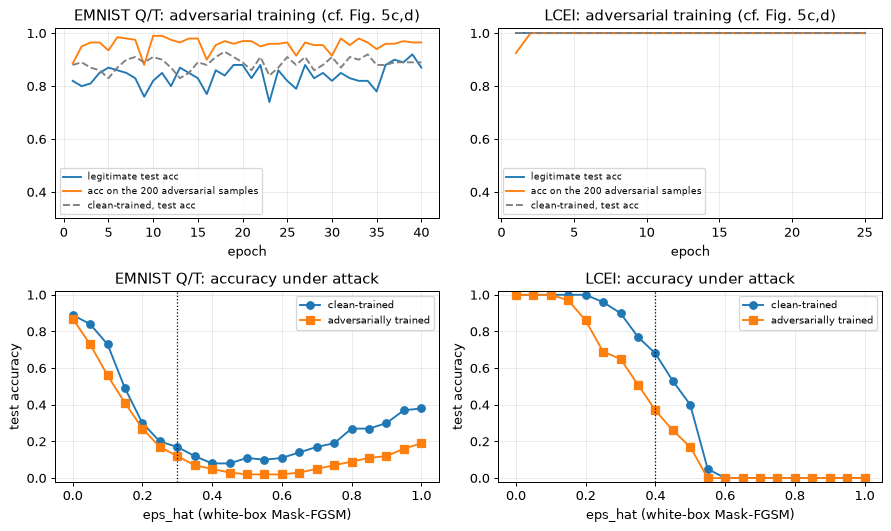

In [22]:
# masks of the adversarially trained models (own gradients, 20 calibration test samples)
M_em_a, frac_em_a, gbar_em_a = make_mask(TASK_EM, th_em_adv, EM_Xte, EM_yte)
M_lc_a, frac_lc_a, gbar_lc_a = make_mask(TASK_LC, th_lc_adv, LC_Xte, LC_yte)

def transfer_acc(task, th_target, Xte_, yte_, th_src, M_src, eps):
    """Accuracy of the target model on adversarial test samples crafted on the clean (source) model."""
    G = input_gradient(task, th_src, Xte_, yte_)
    return accuracy(task, th_target, mask_fgsm(Xte_, G, M_src, eps, task.xrange), yte_)

adv_rows = []
for task, thc, tha, Mc, Ma, Xte_, yte_ in ((TASK_EM, th_em_clean, th_em_adv, M_em, M_em_a, EM_Xte, EM_yte), (TASK_LC, th_lc_clean, th_lc_adv, M_lc, M_lc_a, LC_Xte, LC_yte)):
    Xa, ya, eps = ADV[task.name]
    for tag, th, M in (("clean-trained", thc, Mc), ("adversarially trained", tha, Ma)):
        adv_rows.append(dict(task=task.name, model=tag, eps_hat_train=eps,
                             acc_legit_test=accuracy(task, th, Xte_, yte_),
                             acc_on_200_training_adv=accuracy(task, th, Xa, ya),
                             acc_transfer_adv_test=transfer_acc(task, th, Xte_, yte_, thc, Mc, eps),
                             acc_whitebox_adv_test=float(attack_curve(task, th, Xte_, yte_, M, [eps])[0])))
df_adv = pd.DataFrame(adv_rows)
print(df_adv.round(3).to_string(index=False))

fig, ax = plt.subplots(2, 2, figsize=(10, 6))
for j, (task, hc, ha, thc, tha, Mc, Ma, Xte_, yte_) in enumerate(((TASK_EM, hist_em_clean, hist_em_adv, th_em_clean, th_em_adv, M_em, M_em_a, EM_Xte, EM_yte), (TASK_LC, hist_lc_clean, hist_lc_adv, th_lc_clean, th_lc_adv, M_lc, M_lc_a, LC_Xte, LC_yte))):
    a = ax[0, j]; a.plot(ha.epoch, ha.test_acc, label="legitimate test acc"); a.plot(ha.epoch, ha.adv_acc, label="acc on the 200 adversarial samples"); a.plot(hc.epoch, hc.test_acc, "--", color="gray", label="clean-trained, test acc")
    a.set_title(f"{task.name}: adversarial training (cf. Fig. 5c,d)"); a.set_xlabel("epoch"); a.set_ylim(0.3, 1.02); a.legend(fontsize=7)
    a = ax[1, j]
    a.plot(EPS_ACC, attack_curve(task, thc, Xte_, yte_, Mc, EPS_ACC), "o-", label="clean-trained"); a.plot(EPS_ACC, attack_curve(task, tha, Xte_, yte_, Ma, EPS_ACC), "s-", label="adversarially trained")
    a.axvline(ADV[task.name][2], color="k", ls=":", lw=1); a.set_xlabel("eps_hat (white-box Mask-FGSM)"); a.set_ylabel("test accuracy"); a.set_title(f"{task.name}: accuracy under attack"); a.legend(fontsize=8); a.set_ylim(-0.02, 1.02)
plt.tight_layout(); plt.show()

## 8. Sensitivity, cosine alignment and the robustness score `R_adv` (paper Fig. 3)

**Protocol (reading of Sec. "Adversarial robustness" and Eqs. 9-11).** The paper explains adversarial training as a regulariser `R = (1/2) grad_x L . delta` that turns the input gradient *away from the targeted perturbation `delta`* (the Mask-FGSM direction that generated the 200 training samples). Fig. 3 therefore compares the clean- and adversarially trained models along the **same targeted perturbation** `delta = eps_hat (x_max - x_min) M * sign(grad_x L_clean)` of every sample, and correlates `S` with `cos(delta, grad_x L)` where the gradient belongs to the evaluated model. This notebook reports that protocol (`adversarial`, targeted) as the paper-comparable number, **and** the stricter adaptive protocol in which the adversarially trained model is attacked along its own gradient (`adversarial-adaptive`); the difference between the two is one of the main critical points below.

For every sample of a benchmark set (100 per class) the model is moved along `delta` for a small grid of `eps_hat`; the **sensitivity** is `S = |Delta L| / eps_hat` (slope through the origin of the true-class logit change, `L = ln(p/(1-p))`, Eq. 3) and the **robustness score** is `R_adv = mean(1 / (1 + exp(S)))` (Eq. 4): `R_adv -> 0.5` means the output hardly reacts, `R_adv -> 0` means a tiny perturbation changes the logit a lot.

In [23]:
def direction(task, th_src, X, y, M_src):
    """Targeted perturbation direction per unit eps_hat: (x_max - x_min) * M * sign(grad_x L of the source model)."""
    return task.xrange * M_src * torch.sign(input_gradient(task, th_src, X, y))

def sensitivity(task, th, X, y, D, grid=EPS_SENS):
    """S (B,), cos(delta, grad_x L of this model) (B,), logit changes (E, B), along the fixed direction D."""
    s = 2 * y - 1
    L0 = logit_of(task.z(th, X))
    dL = torch.stack([s * (logit_of(task.z(th, X + e * D)) - L0) for e in grid])                 # true-class logit change
    e = torch.tensor(grid, dtype=torch.float64)[:, None]
    S = ((e * dL).sum(0) / (e * e).sum()).abs()                                                    # CHOICE: slope through the origin, S >= 0
    G = input_gradient(task, th, X, y)
    cos = (D * G).sum(1) / (D.norm(dim=1) * G.norm(dim=1) + 1e-30)
    return S, cos, dL

def p_true(task, th, X, y):                      # probability assigned to the true class
    p1 = (1 + task.z(th, X)) / 2
    return torch.where(y == 1, p1, 1 - p1)

def r_adv(S): return float((1 / (1 + torch.exp(S))).mean())

def bench_indices(y, per_class=BENCH_PER_CLASS, seed=SEED):
    g = np.random.default_rng(seed + 7); yy = np.asarray(y)
    return np.r_[g.choice(np.where(yy == 0)[0], per_class, replace=False), g.choice(np.where(yy == 1)[0], per_class, replace=False)]

EM_Xall, EM_yall = t_em(X_ang), t_lb(emnist_y)
bi_em, bi_lc = bench_indices(emnist_y), bench_indices(lcei_y)
BENCH = {TASK_EM.name: (EM_Xall[bi_em], EM_yall[bi_em]), TASK_LC.name: (LC_X_all[bi_lc], t_lb(lcei_y)[bi_lc])}
TASKS = {TASK_EM.name: TASK_EM, TASK_LC.name: TASK_LC}
# model table: (theta of the evaluated model, own mask, source model of the targeted perturbation)
MODELS = {(TASK_EM.name, "clean"): (th_em_clean, M_em, (th_em_clean, M_em)),
          (TASK_EM.name, "adversarial"): (th_em_adv, M_em_a, (th_em_clean, M_em)),            # paper protocol: the fixed targeted delta
          (TASK_EM.name, "adversarial-adaptive"): (th_em_adv, M_em_a, (th_em_adv, M_em_a)),   # stricter: attacked along its own gradient
          (TASK_LC.name, "clean"): (th_lc_clean, M_lc, (th_lc_clean, M_lc)),
          (TASK_LC.name, "adversarial"): (th_lc_adv, M_lc_a, (th_lc_clean, M_lc)),
          (TASK_LC.name, "adversarial-adaptive"): (th_lc_adv, M_lc_a, (th_lc_adv, M_lc_a))}
DIRS = {k: direction(TASKS[k[0]], v[2][0], *BENCH[k[0]], v[2][1]) for k, v in MODELS.items()}

SENS, rows = {}, []
for (tn, kind), (th, M, _) in MODELS.items():
    Xb, yb = BENCH[tn]
    S, cos, dL = sensitivity(TASKS[tn], th, Xb, yb, DIRS[(tn, kind)])
    SENS[(tn, kind)] = (S, cos)
    pr = pearsonr(S.numpy(), cos.numpy())[0] if S.std() > 0 and cos.std() > 0 else float("nan")
    rows.append(dict(task=tn, model=kind, mean_S=float(S.mean()), median_S=float(S.median()), R_adv=r_adv(S), pearson_S_cos=pr, mean_cos=float(cos.mean()), bench_acc=accuracy(TASKS[tn], th, Xb, yb)))
df_sens = pd.DataFrame(rows)
print(df_sens.round(4).to_string(index=False))
# the paper's scatter (Fig. 3g,h) pools the samples of both training strategies: Pearson correlation of S with cos(delta, grad L) over clean + adversarially trained models
POOLED = {}
for tn in (TASK_EM.name, TASK_LC.name):
    Sc, Cc = SENS[(tn, "clean")]; Sa, Ca = SENS[(tn, "adversarial")]
    POOLED[tn] = pearsonr(torch.cat([Sc, Sa]).numpy(), torch.cat([Cc, Ca]).numpy())[0]
    print(f"{tn}: pooled Pearson(S, cos(delta, grad L)) over clean + adversarial (targeted) samples = {POOLED[tn]:.3f}   (paper: {'0.86' if tn.startswith('EMNIST') else '0.785'})")

      task                model  mean_S  median_S  R_adv  pearson_S_cos  mean_cos  bench_acc
EMNIST Q/T                clean  7.1486    7.3543 0.0040         0.7305    0.6587      0.895
EMNIST Q/T          adversarial  1.8146    1.7759 0.1694        -0.7639   -0.1823      0.815
EMNIST Q/T adversarial-adaptive  5.4965    5.4828 0.0068         0.8983    0.5947      0.815
      LCEI                clean  9.8249    9.2047 0.0010         0.5746    0.7011      1.000
      LCEI          adversarial  1.1463    1.0055 0.2637        -0.4880   -0.1084      1.000
      LCEI adversarial-adaptive  9.8731   10.9781 0.0041         0.3053    0.7521      1.000
EMNIST Q/T: pooled Pearson(S, cos(delta, grad L)) over clean + adversarial (targeted) samples = 0.884   (paper: 0.86)
LCEI: pooled Pearson(S, cos(delta, grad L)) over clean + adversarial (targeted) samples = 0.902   (paper: 0.785)


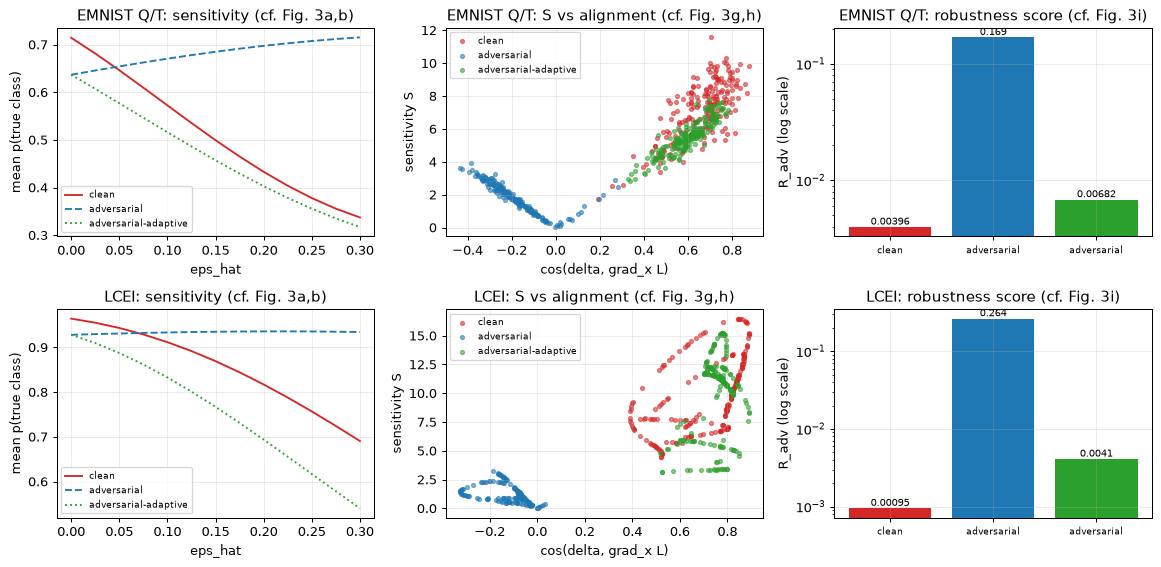

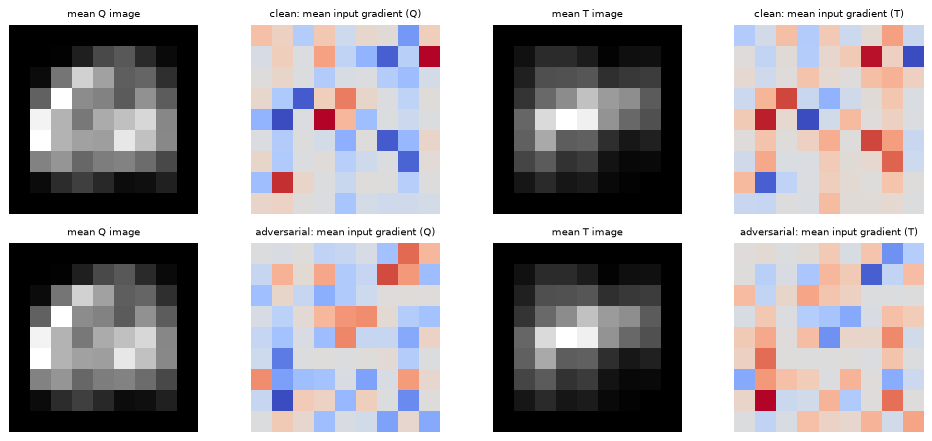

In [24]:
fig, ax = plt.subplots(2, 3, figsize=(13, 6.4))
KINDS = (("clean", "-", "tab:red"), ("adversarial", "--", "tab:blue"), ("adversarial-adaptive", ":", "tab:green"))
for j, tn in enumerate((TASK_EM.name, TASK_LC.name)):
    task = TASKS[tn]; Xb, yb = BENCH[tn]
    a = ax[j, 0]; grid = np.linspace(0, 0.3, 13)
    for kind, ls, col in KINDS:
        th = MODELS[(tn, kind)][0]; D = DIRS[(tn, kind)]
        pt = np.array([[float(p_true(task, th, Xb + e * D, yb)[yb == c].mean()) for c in (0, 1)] for e in grid])
        a.plot(grid, pt.mean(1), ls, color=col, label=kind)
    a.set_xlabel("eps_hat"); a.set_ylabel("mean p(true class)"); a.set_title(f"{tn}: sensitivity (cf. Fig. 3a,b)"); a.legend(fontsize=7)
    a = ax[j, 1]
    for kind, ls, col in KINDS:
        S, cos = SENS[(tn, kind)]; a.scatter(cos.numpy(), S.numpy(), s=10, color=col, alpha=.55, label=kind)
    a.set_xlabel("cos(delta, grad_x L)"); a.set_ylabel("sensitivity S"); a.set_title(f"{tn}: S vs alignment (cf. Fig. 3g,h)"); a.legend(fontsize=7)
    a = ax[j, 2]; sub = df_sens[df_sens.task == tn]
    a.bar(range(len(sub)), sub.R_adv, color=[c for _, _, c in KINDS]); a.set_xticks(range(len(sub))); a.set_xticklabels([k[:11] for k in sub.model], fontsize=7)
    a.set_yscale("log"); a.set_ylabel("R_adv (log scale)"); a.set_title(f"{tn}: robustness score (cf. Fig. 3i)")
    for k, v in enumerate(sub.R_adv): a.text(k, v, f"{v:.3g}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

# average input gradients, clean vs adversarial (cf. Fig. 3d-e): EMNIST pixels
fig, ax = plt.subplots(2, 4, figsize=(11, 5))
Xb, yb = BENCH[TASK_EM.name]
for r, kind in enumerate(("clean", "adversarial")):
    th = MODELS[(TASK_EM.name, kind)][0]
    G = input_gradient(TASK_EM, th, Xb, yb)
    for c in (0, 1):
        gm = G[yb == c].mean(0).reshape(IMG, IMG)
        ax[r, 2 * c].imshow(Xb[yb == c].mean(0).reshape(IMG, IMG), cmap="gray"); ax[r, 2 * c].set_title(f"mean {em_names[c]} image", fontsize=8); ax[r, 2 * c].axis("off")
        ax[r, 2 * c + 1].imshow(gm, cmap="coolwarm", vmin=-gm.abs().max(), vmax=gm.abs().max()); ax[r, 2 * c + 1].set_title(f"{kind}: mean input gradient ({em_names[c]})", fontsize=8); ax[r, 2 * c + 1].axis("off")
plt.tight_layout(); plt.show()

## 9. Classical feed-forward network (FNN) and the matched-size noiseless comparison (paper Table I)

**Main-text comparison.** A three-layer FNN with 81 inputs, a hidden layer of 2 ReLU neurons and one sigmoid output (167 parameters) is trained on the same EMNIST images (9x9) with the same optimiser until its accuracy matches the QNN, then attacked and adversarially trained in the same way. The paper finds the *measured* QNN more than 64x more robust (`R_adv`) and attributes it to noise. Here the QNN is noiseless, so what can be tested is the paper's own noiseless check.

**Table I.** The authors repeat the comparison in noiseless simulation with parameter-matched models: a 3-qubit data re-uploading QNN (`Nr` blocks of 81 data-encoding gates with angle `w_i x_i + b_i`, so `162 Nr` parameters) against an FNN with hidden width `Nh` such that `81 Nh + 2 Nh + 1 ~ 162 Nr`. They report no consistent QNN advantage (both `~0.07`). The re-uploading circuit is only sketched in the paper (`# CHOICE:` here: 9 layers per block, three qubits x three gates `Ry, Rz, Ry` per layer, gate `j` consumes input `j mod 81`, a CZ chain after each layer, read-out `<Z>` on qubit 0).

In [25]:
class FNNTask(Task):
    """81 -> ReLU -> hidden (ReLU) -> 1 (sigmoid). theta is the flat parameter vector; z = 2*sigmoid(out) - 1 so p = (1+z)/2 = sigmoid(out)."""
    def __init__(self, nin, nh, lr, bs, epochs, mask_r, xrange=1.0):
        super().__init__(f"FNN {nin}-{nh}-1", None, "fnn", lr, bs, epochs, mask_r, xrange)
        self.nin, self.nh = nin, nh; self.npar = nin * nh + nh + nh + 1
    def init(self, g):
        s1, s2 = 1 / math.sqrt(self.nin), 1 / math.sqrt(self.nh)
        return torch.tensor(np.r_[g.uniform(-s1, s1, self.nin * self.nh), g.uniform(-s1, s1, self.nh), g.uniform(-s2, s2, self.nh), g.uniform(-s2, s2, 1)])
    def forward(self, theta, X):
        i = self.nin * self.nh
        W1, b1 = theta[:i].reshape(self.nh, self.nin), theta[i:i + self.nh]; W2, b2 = theta[i + self.nh:i + 2 * self.nh].reshape(1, self.nh), theta[i + 2 * self.nh:]
        h = torch.relu(torch.relu(X) @ W1.T + b1)
        out = (h @ W2.T + b2).squeeze(-1)
        return torch.tanh(out / 2), None                 # tanh(out/2) = 2 sigmoid(out) - 1

print("FNN 81-2-1 parameters:", FNNTask(81, 2, .05, 25, 1, .15).npar, "(paper: 167); re-uploading Nr=1 parameters:", ReuploadTask(1, .05, 25, 1, .15).npar, "(paper: 162)")

FNN 81-2-1 parameters: 167 (paper: 167); re-uploading Nr=1 parameters: 162 (paper: 162)


In [26]:
# ---- 9a. FNN comparison on the main EMNIST task ------------------------------------------------
FNN_MAX_EPOCHS = 60 if FAST_MODE else 200
def train_fnn(task, theta0, Xtr, ytr, Xte, yte, target, max_epochs, adv=None, tag=""):
    theta = theta0; hist = []
    for blk in range(0, max_epochs, 5):
        theta, h = train_qnn(task, theta, Xtr, ytr, Xte, yte, 5, adv=adv, seed=SEED + blk, tag=tag, every=10 ** 6)
        # note: Adam state restarts every 5 epochs; fine for a 167-parameter model
        acc = accuracy(task, theta, Xte, yte); hist.append(acc)
        if acc >= target: break
    print(f"[{tag}] stopped after {blk + 5} epochs, test accuracy {acc:.3f} (target {target:.3f})")
    return theta

fnn = FNNTask(81, 2, lr=0.05, bs=25, epochs=0, mask_r=MASK_R_EMNIST, xrange=1.0)
q_target = accuracy(TASK_EM, th_em_clean, EM_Xte, EM_yte)
best = None
for s in range(3):                                                       # a 2-neuron ReLU net can die at initialisation: try 3 seeds
    th0 = fnn.init(np.random.default_rng(SEED + s))
    th = train_fnn(fnn, th0, EM_Xtr, EM_ytr, EM_Xte, EM_yte, q_target, FNN_MAX_EPOCHS, tag=f"FNN clean seed {s}")
    a = accuracy(fnn, th, EM_Xte, EM_yte)
    if best is None or a > best[0]: best = (a, th, th0)
    if a >= q_target: break
fnn_acc, th_fnn_clean, th0_fnn = best
M_fnn, frac_fnn, _ = make_mask(fnn, th_fnn_clean, EM_Xte, EM_yte)
assert fnn.xrange == 1.0 and abs(XRANGE - 1.0) < 1e-12                    # FNN and QNN receive the very same inputs (angle = pixel)
Xa, ya, eps_f = adv_set(fnn, th_fnn_clean, EM_Xtr, EM_ytr, M_fnn)[:3]
print(f"FNN: clean test accuracy {fnn_acc:.3f} (QNN {q_target:.3f}); adversarial training set at eps_hat = {eps_f}")
th_fnn_adv = train_fnn(fnn, th0_fnn, EM_Xtr, EM_ytr, EM_Xte, EM_yte, min(q_target, 0.9), FNN_MAX_EPOCHS, adv=(Xa, ya), tag="FNN adv")
M_fnn_a, _, _ = make_mask(fnn, th_fnn_adv, EM_Xte, EM_yte)

Xb, yb = BENCH[TASK_EM.name]
fnn_rows = []
D_fnn = direction(fnn, th_fnn_clean, Xb, yb, M_fnn)                       # targeted delta of the clean FNN, as for the QNN
for kind, th in (("clean", th_fnn_clean), ("adversarial", th_fnn_adv)):
    S, cos, _ = sensitivity(fnn, th, Xb, yb, D_fnn)
    fnn_rows.append(dict(model=f"FNN {kind}", test_acc=accuracy(fnn, th, EM_Xte, EM_yte), mean_S=float(S.mean()), R_adv=r_adv(S)))
for kind in ("clean", "adversarial"):
    r = df_sens[(df_sens.task == TASK_EM.name) & (df_sens.model == kind)].iloc[0]
    fnn_rows.append(dict(model=f"QNN (simulated, noiseless) {kind}", test_acc=accuracy(TASK_EM, MODELS[(TASK_EM.name, kind)][0], EM_Xte, EM_yte), mean_S=r.mean_S, R_adv=r.R_adv))
df_fnn = pd.DataFrame(fnn_rows)
print(df_fnn.round(5).to_string(index=False))

[FNN clean seed 0] epoch   5/5  loss 0.175  mini-batch acc 0.930  test acc 0.920  (1s)
[FNN clean seed 0] stopped after 5 epochs, test accuracy 0.920 (target 0.890)
FNN: clean test accuracy 0.920 (QNN 0.890); adversarial training set at eps_hat = 0.4


[FNN adv] epoch   5/5  loss 0.224  mini-batch acc 0.906  test acc 0.840  adv acc 0.960  (1s)


[FNN adv] epoch   5/5  loss 0.172  mini-batch acc 0.928  test acc 0.900  adv acc 0.990  (1s)
[FNN adv] stopped after 10 epochs, test accuracy 0.900 (target 0.890)


                                 model  test_acc   mean_S   R_adv
                             FNN clean      0.92 13.02728 0.00292
                       FNN adversarial      0.90  5.15628 0.14225
      QNN (simulated, noiseless) clean      0.89  7.14857 0.00396
QNN (simulated, noiseless) adversarial      0.87  1.81459 0.16937


[re-upload Nr=1] epoch  20/20  loss 0.239  mini-batch acc 0.950  test acc 0.940  (33s)


[FNN Nh=2] epoch  20/20  loss 0.162  mini-batch acc 0.942  test acc 0.920  (3s)


  Nr= 1: QNN 162 params R_adv=0.0000 (acc 0.94) | FNN 167 params R_adv=0.1777 (acc 0.92)


[re-upload Nr=2] epoch  20/20  loss 0.172  mini-batch acc 0.970  test acc 0.930  (35s)


[FNN Nh=4] epoch  20/20  loss 0.015  mini-batch acc 0.998  test acc 0.950  (2s)


...

[FNN Nh=18] epoch  20/20  loss 0.001  mini-batch acc 1.000  test acc 0.970  (4s)


  Nr= 9: QNN 1458 params R_adv=0.0000 (acc 0.91) | FNN 1495 params R_adv=0.1775 (acc 0.97)


[re-upload Nr=10] epoch  20/20  loss 0.694  mini-batch acc 0.576  test acc 0.570  (264s)


[FNN Nh=20] epoch  20/20  loss 0.003  mini-batch acc 0.998  test acc 0.950  (3s)


  Nr=10: QNN 1620 params R_adv=0.0000 (acc 0.57) | FNN 1661 params R_adv=0.1800 (acc 0.95)
 Nr  N_QNN  N_FNN    R_QNN  R_FNN  acc_QNN  acc_FNN  R_QNN_paper  R_FNN_paper
  1    162    167 3.17e-05  0.178     0.94     0.92        0.105        0.075
  2    324    333 8.88e-07  0.153     0.93     0.95        0.104        0.079
  3    486    499 0.000213 0.0501     0.95     0.97        0.077        0.076
  4    648    665 4.96e-06  0.183     0.95     0.97        0.082        0.083
  5    810    831 1.17e-05  0.173     0.98     0.97        0.075        0.089
  6    972    997 6.19e-07   0.15     0.98     0.95         0.04        0.079
  7   1134   1163 0.000107  0.124     0.97     0.95        0.071        0.063
  8   1296   1329 2.55e-05  0.208     0.96     0.97        0.077        0.083
  9   1458   1495 1.39e-05  0.178     0.91     0.97        0.085        0.103
 10   1620   1661 3.08e-05   0.18     0.57     0.95        0.088        0.062


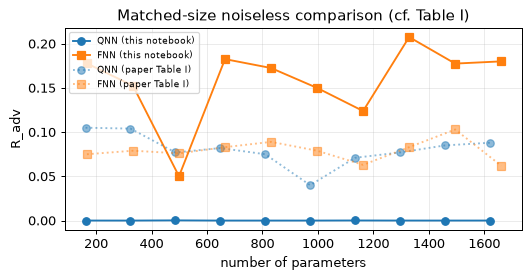

In [27]:
# ---- 9b. Table I: parameter-matched noiseless re-uploading QNN vs FNN --------------------------------------
t1_rows = []
for Nr in TABLE1_SCALES:
    qt = ReuploadTask(Nr, lr=0.03, bs=25, epochs=TABLE1_EPOCHS, mask_r=MASK_R_EMNIST)
    nh = int(round((qt.npar - 1) / 83)); ft = FNNTask(81, nh, lr=0.05, bs=25, epochs=TABLE1_EPOCHS, mask_r=MASK_R_EMNIST)
    gq = np.random.default_rng(SEED + Nr)
    thq, _ = train_qnn(qt, qt.init(gq), EM_Xtr, EM_ytr, EM_Xte, EM_yte, TABLE1_EPOCHS, tag=f"re-upload Nr={Nr}", every=10 ** 6)
    thf, _ = train_qnn(ft, ft.init(gq), EM_Xtr, EM_ytr, EM_Xte, EM_yte, TABLE1_EPOCHS, tag=f"FNN Nh={nh}", every=10 ** 6)
    res = {}
    for nm, tk, th in (("QNN", qt, thq), ("FNN", ft, thf)):
        M, _, _ = make_mask(tk, th, EM_Xte, EM_yte)
        S, _, _ = sensitivity(tk, th, Xb, yb, direction(tk, th, Xb, yb, M))
        res[nm] = (r_adv(S), accuracy(tk, th, EM_Xte, EM_yte))
    t1_rows.append(dict(Nr=Nr, N_QNN=qt.npar, N_FNN=ft.npar, R_QNN=res["QNN"][0], R_FNN=res["FNN"][0], acc_QNN=res["QNN"][1], acc_FNN=res["FNN"][1]))
    print(f"  Nr={Nr:2d}: QNN {qt.npar} params R_adv={res['QNN'][0]:.4f} (acc {res['QNN'][1]:.2f}) | FNN {ft.npar} params R_adv={res['FNN'][0]:.4f} (acc {res['FNN'][1]:.2f})")
df_t1 = pd.DataFrame(t1_rows)
PAPER_T1 = pd.DataFrame(dict(Nr=range(1, 11), R_QNN_paper=[0.105, 0.104, 0.077, 0.082, 0.075, 0.040, 0.071, 0.077, 0.085, 0.088], R_FNN_paper=[0.075, 0.079, 0.076, 0.083, 0.089, 0.079, 0.063, 0.083, 0.103, 0.062]))
df_t1 = df_t1.merge(PAPER_T1, on="Nr", how="left")
print(df_t1.to_string(index=False, float_format=lambda v: f"{v:.3g}"))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(df_t1.N_QNN, df_t1.R_QNN, "o-", label="QNN (this notebook)"); ax.plot(df_t1.N_FNN, df_t1.R_FNN, "s-", label="FNN (this notebook)")
ax.plot(df_t1.N_QNN, df_t1.R_QNN_paper, "o:", color="tab:blue", alpha=.5, label="QNN (paper Table I)"); ax.plot(df_t1.N_FNN, df_t1.R_FNN_paper, "s:", color="tab:orange", alpha=.5, label="FNN (paper Table I)")
ax.set_xlabel("number of parameters"); ax.set_ylabel("R_adv"); ax.set_title("Matched-size noiseless comparison (cf. Table I)"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

## 10. Noise as gradient masking: device-like noise models and the contraction of Eq. (5)

**The paper's explanation.** On the chip the output-qubit Bloch vector is contracted by a depolarising factor `(1 - xi)` per layer, so after `l` layers `z -> (1 - xi)^l z` and the logit sensitivity shrinks by `C(xi, l, z0) = u (1 - z0^2) / (1 - u^2 z0^2)` with `u = (1 - xi)^l` (Eq. 5, proven `< 1`): the noisy QNN reacts less to *every* input change, which raises `R_adv`. The paper stresses that this is gradient attenuation (a hardware-induced regulariser), not an algorithmic advantage.

**Two tests here.**
1. **Gate-level noise on a 6-qubit LCEI QNN** (same architecture family, trained here, clean and adversarially). Density-matrix simulation with (i) a *custom noise model built from the paper's device table S1* (depolarising errors `0.17 %` single-qubit, `1.92 %` two-qubit, native `CZ`; readout error is left out because the paper applies readout-error mitigation) and (ii) the noise model of the IBM `FakeSherbrooke` backend. The attacks are crafted on the noiseless model (white-box) and then evaluated on the noisy circuit, which isolates how noise changes the sensitivity of the *same* circuit.
2. **Analytic contraction on the 10-qubit-class EMNIST model**: Eq. (5) applied to the trained EMNIST QNNs with `xi` computed from the paper's `T1`, `T2` and gate times (`# CHOICE:` 25 ns single-qubit gate, 40 ns CZ), plus a sweep of `u`.

A 6-qubit density matrix is cheap; a 20-qubit (or even 10-qubit EMNIST) density-matrix training/attack campaign is not, which is why the EMNIST model is treated analytically.

In [28]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
from qiskit.transpiler import CouplingMap

# ---- train the 6-qubit LCEI QNN (clean and adversarial) with the same machinery ----
LC6_X_all = t_em(np.repeat(alpha_all[:, None], NOISE_QUBITS, axis=1))
LC6_Xtr, LC6_Xte = LC6_X_all[lc_tr], LC6_X_all[lc_te]
TASK_NZ = Task("LCEI 6-qubit", SPEC_NZ, "state", LR_LCEI, BATCH_LCEI, EPOCHS_LCEI, MASK_R_LCEI, XRANGE_LC)
TH0_NZ = torch.tensor(np.random.default_rng(SEED + 5).uniform(-np.pi, np.pi, SPEC_NZ.npar))
th_nz_clean, _ = train_qnn(TASK_NZ, TH0_NZ, LC6_Xtr, LC_ytr, LC6_Xte, LC_yte, TASK_NZ.epochs, tag="LCEI-6q clean", every=max(1, TASK_NZ.epochs // 4))
M_nz, _, _ = make_mask(TASK_NZ, th_nz_clean, LC6_Xte, LC_yte)
Xa6, ya6, eps6, rows6 = adv_set(TASK_NZ, th_nz_clean, LC6_Xtr, LC_ytr, M_nz)
th_nz_adv, _ = train_qnn(TASK_NZ, TH0_NZ, LC6_Xtr, LC_ytr, LC6_Xte, LC_yte, TASK_NZ.epochs, adv=(Xa6, ya6), tag="LCEI-6q adv", every=max(1, TASK_NZ.epochs // 4))
M_nz_a, _, _ = make_mask(TASK_NZ, th_nz_adv, LC6_Xte, LC_yte)
print(f"6-qubit LCEI QNN: clean test acc {accuracy(TASK_NZ, th_nz_clean, LC6_Xte, LC_yte):.3f}, adversarial test acc {accuracy(TASK_NZ, th_nz_adv, LC6_Xte, LC_yte):.3f} (adversarial set eps_hat = {eps6})")

[LCEI-6q clean] epoch   6/25  loss 0.082  mini-batch acc 1.000  test acc 1.000  (5s)


[LCEI-6q clean] epoch  12/25  loss 0.054  mini-batch acc 1.000  test acc 1.000  (9s)


[LCEI-6q clean] epoch  18/25  loss 0.045  mini-batch acc 1.000  test acc 1.000  (13s)


[LCEI-6q clean] epoch  24/25  loss 0.038  mini-batch acc 1.000  test acc 1.000  (17s)


[LCEI-6q clean] epoch  25/25  loss 0.036  mini-batch acc 1.000  test acc 1.000  (18s)


[LCEI-6q adv] epoch   6/25  loss 0.182  mini-batch acc 1.000  test acc 1.000  adv acc 1.000  (5s)


[LCEI-6q adv] epoch  12/25  loss 0.117  mini-batch acc 1.000  test acc 1.000  adv acc 1.000  (9s)


[LCEI-6q adv] epoch  18/25  loss 0.102  mini-batch acc 1.000  test acc 1.000  adv acc 1.000  (13s)


[LCEI-6q adv] epoch  24/25  loss 0.061  mini-batch acc 1.000  test acc 1.000  adv acc 1.000  (18s)


[LCEI-6q adv] epoch  25/25  loss 0.061  mini-batch acc 1.000  test acc 1.000  adv acc 1.000  (19s)
6-qubit LCEI QNN: clean test acc 1.000, adversarial test acc 1.000 (adversarial set eps_hat = 0.4)


In [29]:
# ---- noisy simulation machinery ----
def paper_device_noise(basis=("rz", "sx", "x", "cz")):
    nm = NoiseModel(basis_gates=list(basis))   # noise on sx, x, cz; rz is virtual (error free)
    p1, p2 = 4 * ERR_1Q / 3, 16 * ERR_2Q / 15                    # Pauli error e = 3p/4 (1 qubit), 15p/16 (2 qubits)
    nm.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["sx", "x"])
    nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cz"])
    return nm

def build_noisy_runner(spec, theta, kind):
    """Return (run(alphas)->z array, transpiled circuit). kind: 'ideal' | 'paper' | 'fake'. alphas: (B, n) numpy angles."""
    n = spec.n; a_p = ParameterVector("a", n)
    qc = qiskit_qnn(spec, np.asarray(theta), None, a_p)
    if kind == "paper":                                            # linear chain with the identity layout: no SWAPs needed (nearest-neighbour CZ only)
        sim = AerSimulator(method="density_matrix", noise_model=paper_device_noise())
        tqc = transpile(qc, basis_gates=["rz", "sx", "x", "cz"], coupling_map=CouplingMap.from_line(n), initial_layout=list(range(n)), optimization_level=1, seed_transpiler=SEED)
    else:
        sim = AerSimulator(method="density_matrix") if kind == "ideal" else AerSimulator.from_backend(FakeSherbrooke(), method="density_matrix")
        tqc = transpile(qc, sim, optimization_level=1, seed_transpiler=SEED)
    phys = tqc.layout.final_index_layout()[spec.out] if tqc.layout is not None else spec.out      # physical qubit that holds the logical output qubit
    tqc.save_density_matrix([phys], label="rho")
    def run(alphas):
        circs = [tqc.assign_parameters(dict(zip(a_p, map(float, a)))) for a in np.asarray(alphas)]
        res = sim.run(circs, shots=1).result()
        out = []
        for i in range(len(circs)):
            r = np.asarray(res.data(i)["rho"]); out.append((r[0, 0] - r[1, 1]).real)
        return torch.tensor(np.array(out))
    return run, tqc

# sanity: noiseless Aer density-matrix run reproduces the PyTorch engine
run_id, tqc_id = build_noisy_runner(SPEC_NZ, to_np(th_nz_clean), "ideal")
chk = LC6_Xte[:5]
assert np.allclose(to_np(run_id(to_np(chk))), to_np(TASK_NZ.z(th_nz_clean, chk)), atol=1e-8)
print("noiseless Aer density matrix == PyTorch engine (assertion passed); transpiled depth:", tqc_id.depth(), " ops:", dict(tqc_id.count_ops()))

noiseless Aer density matrix == PyTorch engine (assertion passed); transpiled depth: 25  ops: {'u3': 36, 'cz': 20, 'barrier': 10, 'rx': 7, 'h': 6, 'save_density_matrix': 1}


In [30]:
NZ_MODELS = {"clean": (th_nz_clean, th_nz_clean, M_nz), "adversarial": (th_nz_adv, th_nz_clean, M_nz)}      # (evaluated model, source of the targeted delta, its mask)
bi_nz = bench_indices(lcei_y, per_class=NOISE_N_STATES // 2)
Xb6, yb6 = LC6_X_all[bi_nz], t_lb(lcei_y)[bi_nz]
noise_rows, noise_z = [], {}
for kind, (th, th_src, M_src) in NZ_MODELS.items():
    D6 = direction(TASK_NZ, th_src, Xb6, yb6, M_src)                                       # targeted delta, crafted on the noiseless clean model
    inputs = [Xb6] + [Xb6 + e * D6 for e in EPS_SENS]
    flat = torch.cat(inputs)
    z_ideal = TASK_NZ.z(th, flat)
    for nk in ("paper", "fake"):
        t0 = time.time(); run, tqc = build_noisy_runner(SPEC_NZ, to_np(th), nk); z_noisy = run(to_np(flat))
        B = len(Xb6)
        zi, zn = z_ideal.reshape(len(inputs), B), z_noisy.reshape(len(inputs), B)
        s = 2 * yb6 - 1; e = torch.tensor(EPS_SENS, dtype=torch.float64)[:, None]
        def S_of(z):
            dL = s * (logit_of(z[1:]) - logit_of(z[0])); return ((e * dL).sum(0) / (e * e).sum()).abs()
        S_i, S_n = S_of(zi), S_of(zn)
        u = float((zn * zi).sum() / (zi * zi).sum())                                          # effective contraction z_noisy ~ u * z_ideal
        z0 = zi[0]; Cpred = u * (1 - z0 ** 2) / (1 - u ** 2 * z0 ** 2)
        noise_z[(kind, nk)] = (zi, zn)
        noise_rows.append(dict(model=kind, noise=nk, acc_ideal=float(((zi[0] > 0).long() == yb6.long()).double().mean()), acc_noisy=float(((zn[0] > 0).long() == yb6.long()).double().mean()),
                               u_eff=u, mean_S_ideal=float(S_i.mean()), mean_S_noisy=float(S_n.mean()), S_ratio=float(S_n.mean() / S_i.mean()), Eq5_pred_ratio=float((Cpred * S_i).mean() / S_i.mean()),
                               R_adv_ideal=r_adv(S_i), R_adv_noisy=r_adv(S_n), transpiled_depth=tqc.depth(), sec=time.time() - t0))
df_noise = pd.DataFrame(noise_rows)
print(df_noise.round(4).to_string(index=False))

      model noise  acc_ideal  acc_noisy  u_eff  mean_S_ideal  mean_S_noisy  S_ratio  Eq5_pred_ratio  R_adv_ideal  R_adv_noisy  transpiled_depth     sec
      clean paper        1.0        1.0 0.6070        8.8925        1.0742   0.1208          0.0994       0.0064       0.2881                71 18.3953
      clean  fake        1.0        1.0 0.7841        8.8925        1.8450   0.2075          0.1800       0.0064       0.2033               102 49.1948
adversarial paper        1.0        1.0 0.6884        0.3070        0.0441   0.1438          0.1641       0.4253       0.4890                71 23.8183
adversarial  fake        1.0        1.0 0.8256        0.3070        0.0738   0.2405          0.2669       0.4253       0.4816               102 46.5243


xi per layer = 0.0287 (Eq. S35 approx 0.0293), layers l = 12, contraction u = (1-xi)^l = 0.705


      model       u  S_ideal  S_noisy_Eq5  S_ratio  R_adv_ideal  R_adv_Eq5_noisy  acc_noisy
      clean 0.70513  7.14857      4.19128  0.58631      0.00396          0.02993       0.89
adversarial 0.70513  1.81459      1.16575  0.64243      0.16937          0.25138       0.87


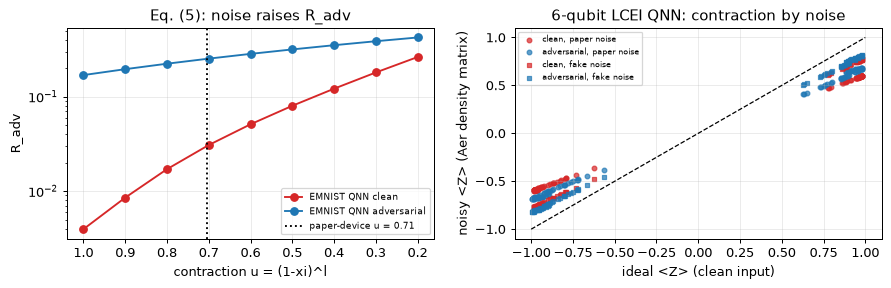

IBM_TOKEN empty: real-hardware cell skipped (as designed).


In [31]:
# ---- 10b. Eq. (5) applied to the EMNIST QNN: xi from the paper's T1, T2, and a sweep of the contraction u ----
def xi_from_T(t_us, T1=T1_US, T2=T2_US):
    return 1 - (2 * math.exp(-t_us * (1 / (2 * T1) + 1 / T2)) + math.exp(-t_us / T1)) / 3          # Eq. (S34)

t_layer_us = (2 * T_1Q_NS + T_2Q_NS) / 1000.0                    # CHOICE: two physical Rx(pi/2) pulses + one CZ per SU(2)+CZ block
xi = xi_from_T(t_layer_us); L_layers = len(SPEC_EM.blocks); u_dev = (1 - xi) ** L_layers
print(f"xi per layer = {xi:.4f} (Eq. S35 approx {2 / 3 * (1 / T1_US + 1 / T2_US) * t_layer_us:.4f}), layers l = {L_layers}, contraction u = (1-xi)^l = {u_dev:.3f}")

def r_adv_contracted(task, th, D, X, y, u, grid=EPS_SENS):
    s = 2 * y - 1
    z0 = task.z(th, X); L0 = logit_of(u * z0)
    dL = torch.stack([s * (logit_of(u * task.z(th, X + e * D)) - L0) for e in grid])
    e = torch.tensor(grid, dtype=torch.float64)[:, None]
    S = ((e * dL).sum(0) / (e * e).sum()).abs()
    return S, r_adv(S)

u_grid = np.array([1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2])
Xb, yb = BENCH[TASK_EM.name]
eq5_rows, curves = [], {}
for kind in ("clean", "adversarial"):
    th = MODELS[(TASK_EM.name, kind)][0]; D = DIRS[(TASK_EM.name, kind)]
    curves[kind] = [r_adv_contracted(TASK_EM, th, D, Xb, yb, float(u))[1] for u in u_grid]
    S_i, R_i = r_adv_contracted(TASK_EM, th, D, Xb, yb, 1.0); S_n, R_n = r_adv_contracted(TASK_EM, th, D, Xb, yb, u_dev)
    eq5_rows.append(dict(model=kind, u=u_dev, S_ideal=float(S_i.mean()), S_noisy_Eq5=float(S_n.mean()), S_ratio=float(S_n.mean() / S_i.mean()), R_adv_ideal=R_i, R_adv_Eq5_noisy=R_n,
                         acc_noisy=float((((u_dev * TASK_EM.z(th, EM_Xte)) > 0).long() == EM_yte.long()).double().mean())))
df_eq5 = pd.DataFrame(eq5_rows); print(df_eq5.round(5).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
for kind, col in (("clean", "tab:red"), ("adversarial", "tab:blue")):
    ax[0].plot(u_grid, curves[kind], "o-", color=col, label=f"EMNIST QNN {kind}")
ax[0].axvline(u_dev, color="k", ls=":", label=f"paper-device u = {u_dev:.2f}"); ax[0].set_xlabel("contraction u = (1-xi)^l"); ax[0].set_ylabel("R_adv"); ax[0].set_yscale("log"); ax[0].set_title("Eq. (5): noise raises R_adv"); ax[0].legend(fontsize=7); ax[0].invert_xaxis()
for nk, mk in (("paper", "o"), ("fake", "s")):
    for kind, col in (("clean", "tab:red"), ("adversarial", "tab:blue")):
        zi, zn = noise_z[(kind, nk)]; ax[1].scatter(zi[0], zn[0], marker=mk, color=col, s=14, alpha=.7, label=f"{kind}, {nk} noise")
ax[1].plot([-1, 1], [-1, 1], "k--", lw=1); ax[1].set_xlabel("ideal <Z> (clean input)"); ax[1].set_ylabel("noisy <Z> (Aer density matrix)"); ax[1].set_title("6-qubit LCEI QNN: contraction by noise"); ax[1].legend(fontsize=6)
plt.tight_layout(); plt.show()

if IBM_TOKEN:
    print("IBM_TOKEN is set, but this notebook ships no hardware job (the paper's chip is not an IBM device); skipping.")
else:
    print("IBM_TOKEN empty: real-hardware cell skipped (as designed).")

## 11. Side by side with the paper: one verdict per claim

Verdict rules (fixed before looking at the numbers): accuracies are `reproduced` within 2 accuracy points, otherwise `not reached here` (lower) or `exceeded here` (higher); the bound gap is `reproduced` if it is of the paper's order of magnitude (<= 1e-2) *and* `R_UB >= R_LB` holds for every sample; correlations within 0.1; `R_adv` values within a factor of 2 (they depend on the unspecified `eps_hat` grid); qualitative claims are checked as stated. Anything that needs the physical chip is `cannot be checked`.

In [32]:
def v_acc(paper, ours, tol=0.02):
    if ours >= paper - tol and ours <= paper + tol: return "reproduced"
    return "exceeded here" if ours > paper else "not reached here"
def v_ratio(paper, ours, factor=2.0):
    if ours <= 0 or paper <= 0: return "not reached here"
    r = ours / paper
    return "reproduced" if (1 / factor) <= r <= factor else ("exceeded here" if r > factor else "not reached here")
def v_corr(paper, ours, tol=0.1):
    if not np.isfinite(ours): return "cannot be checked"
    return "reproduced" if abs(ours - paper) <= tol else ("exceeded here" if ours > paper else "not reached here")
def get(df, **kw):
    m = np.ones(len(df), bool)
    for k, v in kw.items(): m &= (df[k] == v).values
    return df[m].iloc[0]

cr = {r["task"]: r for r in clean_rows}
em_c, lc_c = cr[TASK_EM.name], cr[TASK_LC.name]
ad = {(r.task, r.model): r for r in df_adv.itertuples()}
sd = {(r.task, r.model): r for r in df_sens.itertuples()}
gap = {n: bnd[n][0][bnd[n][0].crossed] for n in bnd}
gap_em, gap_lc = gap[TASK_EM.name], gap[TASK_LC.name]
claims = []
def add(c, paper, ours, verdict): claims.append(dict(claim=c, paper=paper, notebook=ours, verdict=verdict))

add("EMNIST clean QNN train accuracy", "0.98 (hardware)", f"{em_c['train_acc']:.3f}", v_acc(0.98, em_c["train_acc"]))
add("EMNIST clean QNN test accuracy", "0.96 (hardware)", f"{em_c['test_acc']:.3f}", v_acc(0.96, em_c["test_acc"]))
add("LCEI clean QNN train accuracy", "1.00", f"{lc_c['train_acc']:.3f}", v_acc(1.0, lc_c["train_acc"]))
add("LCEI clean QNN test accuracy", "1.00", f"{lc_c['test_acc']:.3f}", v_acc(1.0, lc_c["test_acc"]))
a = ad[(TASK_EM.name, "adversarially trained")]
add("EMNIST adv.-trained: accuracy on legitimate samples", "0.88", f"{a.acc_legit_test:.3f}", v_acc(0.88, a.acc_legit_test))
add("EMNIST adv.-trained: accuracy on the 200 adversarial samples", "0.87", f"{a.acc_on_200_training_adv:.3f}", v_acc(0.87, a.acc_on_200_training_adv))
a = ad[(TASK_LC.name, "adversarially trained")]
add("LCEI adv.-trained: accuracy on legitimate samples", "1.00", f"{a.acc_legit_test:.3f}", v_acc(1.0, a.acc_legit_test))
add("LCEI adv.-trained: accuracy on the 200 adversarial samples", "1.00", f"{a.acc_on_200_training_adv:.3f}", v_acc(1.0, a.acc_on_200_training_adv))
ge = gap_em.gap.mean() if len(gap_em) else float("nan"); gl = gap_lc.gap.mean() if len(gap_lc) else float("nan")
add("EMNIST: gap R_UB - R_LB (10 samples)", "2.96e-3 (hardware)", f"{ge:.2e} ({len(gap_em)} samples flipped)", "reproduced" if (np.isfinite(ge) and ge <= 1e-2 and (gap_em.R_UB >= gap_em.R_LB - 1e-9).all()) else "not reached here")
add("LCEI: gap R_UB - R_LB (10 samples)", "3.25e-3 (hardware)", f"{gl:.2e} ({len(gap_lc)} samples flipped)", "reproduced" if (np.isfinite(gl) and gl <= 1e-2 and (gap_lc.R_UB >= gap_lc.R_LB - 1e-9).all()) else "not reached here")
add("Lower bound is certified (R_UB >= R_LB for every sample)", "holds", "holds" if all((g_.R_UB >= g_.R_LB - 1e-9).all() for g_ in gap.values()) else "VIOLATED", "reproduced" if all((g_.R_UB >= g_.R_LB - 1e-9).all() for g_ in gap.values()) else "not reached here")
add("EMNIST Pearson(S, cos(delta, grad L)), clean + adversarial pooled", "0.86", f"{POOLED[TASK_EM.name]:.3f} (clean alone {sd[(TASK_EM.name, 'clean')].pearson_S_cos:.3f})", v_corr(0.86, POOLED[TASK_EM.name]))
add("LCEI Pearson(S, cos(delta, grad L)), clean + adversarial pooled", "0.785", f"{POOLED[TASK_LC.name]:.3f} (clean alone {sd[(TASK_LC.name, 'clean')].pearson_S_cos:.3f})", v_corr(0.785, POOLED[TASK_LC.name]))
for tn, pc, pa in ((TASK_EM.name, 8.90e-3, 0.330), (TASK_LC.name, 0.105, 0.339)):
    rc, ra = sd[(tn, "clean")].R_adv, sd[(tn, "adversarial")].R_adv
    add(f"{tn}: R_adv clean-trained", f"{pc:.3g} (hardware)", f"{rc:.3g}", v_ratio(pc, rc))
    add(f"{tn}: R_adv adversarially trained", f"{pa:.3g} (hardware)", f"{ra:.3g}", v_ratio(pa, ra))
    add(f"{tn}: adversarial training raises R_adv and lowers S", "yes", f"R_adv {rc:.3g} -> {ra:.3g}; mean S {sd[(tn, 'clean')].mean_S:.3g} -> {sd[(tn, 'adversarial')].mean_S:.3g}",
        "reproduced" if (ra > rc and sd[(tn, 'adversarial')].mean_S < sd[(tn, 'clean')].mean_S) else "not reached here")
dif = (df_t1.R_QNN - df_t1.R_FNN)
add("Table I: no consistent QNN advantage over a matched FNN (noiseless)", "both ~0.07, sign of the gap fluctuates",
    f"mean R_QNN {df_t1.R_QNN.mean():.2g} vs mean R_FNN {df_t1.R_FNN.mean():.2g}; QNN larger in {(dif > 0).sum()}/{len(dif)} scales; QNN accuracy range {df_t1.acc_QNN.min():.2f}-{df_t1.acc_QNN.max():.2f}",
    "reproduced" if (abs(dif.mean()) < 0.03 and (dif > 0).sum() not in (0, len(dif))) or len(dif) < 3 and abs(dif.mean()) < 0.03 else "not reached here")
q, f_ = get(df_fnn, model="QNN (simulated, noiseless) clean"), get(df_fnn, model="FNN clean")
ratio = q.R_adv / max(f_.R_adv, 1e-300)
add("Noiseless regime, main task: QNN is not more robust than a classical FNN", "no consistent advantage (Table I, noiseless)", f"R_adv QNN {q.R_adv:.3g} vs FNN {f_.R_adv:.3g} (ratio {ratio:.2f}, accuracies {q.test_acc:.2f} / {f_.test_acc:.2f})", "reproduced" if 1 / 3 <= ratio <= 3 else "not reached here")
r5 = get(df_eq5, model="clean").R_adv_Eq5_noisy
add("Noise-contracted QNN (Eq. 5, paper-device T1/T2) vs FNN, main task", ">64x on the chip (measured)", f"R_adv {r5:.3g} vs FNN {f_.R_adv:.3g} (ratio {r5 / max(f_.R_adv, 1e-300):.1f}x); not a chip measurement", "cannot be checked")
for r in df_noise.itertuples():
    add(f"Noise raises R_adv (6-qubit LCEI QNN, {r.model}-trained, {r.noise} noise)", "yes (Eq. 5: S shrinks by C < 1)", f"S ratio {r.S_ratio:.2f} (Eq.5 predicts {r.Eq5_pred_ratio:.2f}); R_adv {r.R_adv_ideal:.3g} -> {r.R_adv_noisy:.3g}",
        "reproduced" if (r.R_adv_noisy >= r.R_adv_ideal and r.S_ratio < 1) else "not reached here")
for tn in (TASK_EM.name, TASK_LC.name):
    ra = sd[(tn, "adversarial-adaptive")]
    add(f"{tn}: adversarially trained model attacked adaptively along its own gradient (not in the paper)", "not tested (static adversarial set)", f"R_adv {ra.R_adv:.3g}, mean S {ra.mean_S:.3g}", "cannot be checked")
add("Hardware-only numbers (20-qubit chip: QST, shots, robustness scores in Fig. 3i, 64x vs FNN)", "chip", "not simulated at 20 qubits", "cannot be checked")
df_claims = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 220)
print(df_claims.to_string(index=False))
print("\nverdict counts:", df_claims.verdict.value_counts().to_dict())

                                                                                                claim                                        paper                                                                                       notebook           verdict
                                                                      EMNIST clean QNN train accuracy                              0.98 (hardware)                                                                                          0.888  not reached here
                                                                       EMNIST clean QNN test accuracy                              0.96 (hardware)                                                                                          0.890  not reached here
                                                                        LCEI clean QNN train accuracy                                         1.00                                                                          

## 12. Reading the paper critically

* **Hardware vs simulation.** The paper's headline numbers come from a 20-qubit chip with shots, readout mitigation and tomography; this notebook re-runs the *protocol* on exact simulators with a smaller 8-qubit circuit and 9x9 images. Where a claim is `cannot be checked` it genuinely needs the chip (or at least a 20-qubit noisy campaign); where a number differs it may be due to the smaller model, the unspecified training budget, the `eps_hat` grid, or the pixel-to-angle scale (all documented above), not to a flaw in the paper.
* **`R_adv` is not a property of the model alone.** It depends on the step grid `eps_hat`, on the mask, on the logit saturation, and on the normalisation `x_max - x_min`. A model that saturates (`|z| ~ 1`) has a huge logit gradient, and the paper's "64x" and "8.9e-3 -> 0.330" are only meaningful relative to the same protocol.
* **Gradient masking, as the authors admit.** The noise argument (Eq. 5) shows that noise shrinks the sensitivity of *every* input direction, so a stronger or noise-aware attacker (more iterations, larger `eps_hat`, expectation over noise) is not stopped; a noisy model is also less accurate. Section 10 reproduces the mechanism and shows that it is a contraction of the logit scale, not new robustness of the decision boundary.
* **The adversarial set is static, and so is the Fig. 3 evaluation.** The 200 adversarial samples are generated once on the clean model, and the sensitivity comparison moves both models along that same targeted `delta`; adversarial training then *rotates the gradient away from `delta`* (the regulariser of Eq. 11), which lowers `S` along `delta` but need not lower it along other directions. Compare the `adversarial` (targeted) and `adversarial-adaptive` rows of section 8 and the white-box accuracy curves of section 7: an attacker who recomputes the gradient on the adversarially trained model typically finds it as fragile as, or more fragile than, the clean model. That limitation is consistent with the authors' own remark that adversarial training is only a patch against known attacks.
* **Small statistics.** The bound experiment uses ten samples, the test sets have 100 samples (one sample = 1 point of accuracy), the EMNIST task is two letters. Our results come from one seed; differences of a few points are within noise.
* **A certified radius in infidelity** is a statement about the output-qubit state, not about pixel perturbations; the near-tightness of `R_UB` and `R_LB` for a single output qubit read by `Z` reflects that the attack can flip the output qubit along a nearly optimal direction, which says little about robustness against arbitrary input perturbations.
* **The classical baseline is tiny.** A 2-neuron-hidden FNN is a weak classifier; the authors' own noiseless Table I removes the apparent QNN advantage, which suggests that the 64x gap is driven by noise-induced attenuation rather than by quantum-ness.

## 13. Exercises

1. **Seeds.** Change `SEED` (and the initial `theta`) and rerun sections 4-8. How large is the seed-to-seed spread of the test accuracy, of `R_adv`, and of the Pearson correlation? Which verdicts flip?
2. **Pixel scale.** Set `XRANGE = math.pi` (angle = pi x pixel). What happens to the clean accuracy and to `R_adv`? Why does the sensitivity change by the same factor when `eps_hat` is defined as `eps / (x_max - x_min)`?
3. **Mask size.** Sweep the mask ratio `r` from 0.05 to 1.0 and plot the accuracy under attack at a fixed `eps_hat`. Where does the curve saturate? Compare with the paper's `G_r / G` elbow (Fig. S5/S7).
4. **Stronger defence evaluation.** Replace the static adversarial set by a fresh Mask-FGSM batch generated from the *current* model at every epoch (true adversarial training) and compare `R_adv` and the white-box accuracy curve.
5. **Noise level.** In the Aer cell scale `ERR_1Q` and `ERR_2Q` by 0.5, 2 and 4. Plot the 6-qubit model's accuracy and `R_adv` against the effective contraction `u`. At which noise level does the "robustness" come at the price of lost clean accuracy?